# Méthode de Levenberg–Marquardt

## 0. Imports et configuration

In [33]:
import time
from dataclasses import dataclass, field

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_triangular
from scipy.optimize import least_squares, brentq

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 11})
np.set_printoptions(precision=4, suppress=True)
print("Imports OK — NumPy", np.__version__)

Imports OK — NumPy 2.4.6


## 1. Formulation : résidus, jacobienne, gradient, hessienne
On cherche $\min_x F(x)=\tfrac12\sum_{i=1}^m r_i(x)^2$. Les outils de base sont :

- la **jacobienne** $J_{ij}=\partial r_i/\partial x_j$ : la ligne $i$ dit comment l'erreur $r_i$ réagit à chaque inconnue ; l'erreur change d'environ $J\,\Delta x$ après un déplacement $\Delta x$ ;
- le **gradient** $\nabla F=J^\top r$ ;
- la **hessienne** $\nabla^2F={J^\top J}+{\sum_i r_i\nabla^2 r_i}$ . La partie 2 est pondérée par les résidus : elle est négligeable quand ils sont petits ou quand le modèle est presque linéaire.

In [35]:
r_ex = lambda x: np.array([x[0] * x[1] - 1, x[0] ** 2 + x[1] - 3])
J_ex = lambda x: np.array([[x[1], x[0]], [2 * x[0], 1.0]])
x_ex = np.array([2.0, 1.0])

print("J(2,1) =\n", J_ex(x_ex), "   (le rapport donne [[1, 2], [4, 1]])")
print("r(2,1) =", r_ex(x_ex))

# Lecture de la 1re ligne : x1 + 0,01 => r1 + ~0,01 ; x2 + 0,01 => r1 + ~0,02
for j, nom in enumerate(["x1", "x2"]):
    dx = np.zeros(2); dx[j] = 0.01
    print(f"{nom} += 0.01 : variation réelle de r = {r_ex(x_ex + dx) - r_ex(x_ex)}   prédiction J·dx = {J_ex(x_ex) @ dx}")

# Hessienne : exacte (différences finies du gradient) contre JtJ + somme r_i ∇²r_i
grad = lambda x: J_ex(x).T @ r_ex(x)
eps = 1e-6
H_fd = np.column_stack([(grad(x_ex + eps * e) - grad(x_ex - eps * e)) / (2 * eps) for e in np.eye(2)])
partie1 = J_ex(x_ex).T @ J_ex(x_ex)
hess_r1, hess_r2 = np.array([[0, 1], [1, 0.0]]), np.array([[2, 0], [0, 0.0]])
partie2 = r_ex(x_ex)[0] * hess_r1 + r_ex(x_ex)[1] * hess_r2
print("\nPartie 1 (JᵀJ) =\n", partie1, "\nPartie 2 (Σ r_i ∇²r_i) =\n", partie2)
print("Somme =\n", partie1 + partie2, "\nHessienne par différences finies =\n", H_fd)
assert np.allclose(partie1 + partie2, H_fd, atol=1e-5)

J(2,1) =
 [[1. 2.]
 [4. 1.]]    (le rapport donne [[1, 2], [4, 1]])
r(2,1) = [1. 2.]
x1 += 0.01 : variation réelle de r = [0.01   0.0401]   prédiction J·dx = [0.01 0.04]
x2 += 0.01 : variation réelle de r = [0.02 0.01]   prédiction J·dx = [0.02 0.01]

Partie 1 (JᵀJ) =
 [[17.  6.]
 [ 6.  5.]] 
Partie 2 (Σ r_i ∇²r_i) =
 [[4. 1.]
 [1. 0.]]
Somme =
 [[21.  7.]
 [ 7.  5.]] 
Hessienne par différences finies =
 [[21.  7.]
 [ 7.  5.]]


## 2. Implémentation de LM *from scratch*

### 2.1 Le pas : équations normales ou factorisation QR

Gauss–Newton résout $(J^\top J)\Delta x=-J^\top r$. **Levenberg–Marquardt** ajoute $\lambda$ sur la diagonale :

$$(J^\top J+\lambda I)\,\Delta x=-J^\top r.$$

Deux façons équivalentes de calculer $\Delta x$ :

1. **équations normales** : on forme $J^\top J+\lambda I$ et on résout le système $n\times n$ ($\approx mn^2$ opérations) ;
2. **QR de la matrice empilée**: $\Delta x$ est la solution des moindres carrés ordinaires de
$\begin{pmatrix}J\\ \sqrt{\lambda}\,I\end{pmatrix}\Delta x\approx\begin{pmatrix}-r\\ 0\end{pmatrix}$, de taille $(m+n)\times n$, pour $\approx 2(m+n)n^2$ opérations. Le conditionnement de $J^\top J$ est le **carré** de celui de $J$ ; la QR évite ce carré.

Le paramètre `damping` choisit la matrice d'amortissement $D$ : `"identity"` ($D=I$, Levenberg) ou `"marquardt"` ($D=\mathrm{diag}(J^\top J)$, variante qui rend le pas insensible à l'échelle des variables).

### 2.2 Critères d'arrêt
On s'arrête si (i) $\|r\|^2$ est presque nul (équations quasi résolues), (ii) $\|J^\top r\|$ est presque nul (sol plat), ou (iii) le nombre maximal d'itérations est atteint. On ajoute une garde sur $\lambda$ trop grand (stagnation) et, en option, un test sur la décroissance relative du coût.

In [36]:
@dataclass
class LMResult:
    """Résultat d'une exécution de LM."""
    x: np.ndarray
    F_hist: list = field(default_factory=list)      # F après chaque pas accepté (F_hist[0] = coût initial)
    lam_hist: list = field(default_factory=list)    # λ utilisé à chaque essai
    x_hist: list = field(default_factory=list)      # trajectoire des itérés acceptés
    trials: list = field(default_factory=list)      # un dict par essai (k, λ, x, x_essai, F, F_essai, ρ, g·Δx, accepté)
    nfev: int = 0          # évaluations de r
    njev: int = 0          # évaluations de J
    n_iter: int = 0        # essais (acceptés + rejetés)
    n_rejected: int = 0
    status: str = ""

    @property
    def cost(self):                 # F final
        return self.F_hist[-1]
    @property
    def n_accepted(self):
        return self.n_iter - self.n_rejected


def lm_step(r, J, lam, damping="identity", solver="qr"):
    """Pas de LM : résout (JᵀJ + λD) Δx = −Jᵀr."""
    n = J.shape[1]
    d = np.ones(n) if damping == "identity" else np.maximum(np.sum(J ** 2, axis=0), 1e-12)   # D = I ou diag(JᵀJ)
    if solver == "normal":                                   # équations normales
        return np.linalg.solve(J.T @ J + lam * np.diag(d), -(J.T @ r))
    M = np.vstack([J, np.sqrt(lam) * np.diag(np.sqrt(d))])  # matrice empilée (m+n) × n
    rhs = np.concatenate([-r, np.zeros(n)])
    Q, R = np.linalg.qr(M)                                  # factorisation QR « réduite »
    return solve_triangular(R, Q.T @ rhs)                   # R Δx = Qᵀ rhs


def levenberg_marquardt(residuals, jacobian, x0, lam0=1.0, max_iter=200, tol_r=1e-12, tol_g=1e-8,
                        tol_f=0.0, rule="book", damping="identity", solver="qr", lam_max=1e16,
                        book_down=0.8, book_up=2.0, verbose=False):
    x = np.asarray(x0, dtype=float).copy()
    res = LMResult(x=x)
    r = residuals(x); res.nfev = 1
    F = 0.5 * r @ r
    J = jacobian(x); res.njev = 1
    lam = lam0
    res.F_hist.append(F); res.x_hist.append(x.copy()); res.status = "max_iter"
    if verbose:
        print(f"{'it':>3} {'lambda':>10} {'F essai':>12} {'rho':>8}  decision")

    for k in range(max_iter):
        g = J.T @ r
        if np.linalg.norm(g) < tol_g:  res.status = "gradient"; break      # (ii) sol presque plat
        if 2 * F < tol_r:              res.status = "residu";   break      # (i) équations presque résolues
        dx = lm_step(r, J, lam, damping, solver)
        x_try = x + dx
        r_try = residuals(x_try); res.nfev += 1
        F_try = 0.5 * r_try @ r_try
        pred = F - 0.5 * np.sum((r + J @ dx) ** 2)           # diminution prédite par la tangente
        rho = (F - F_try) / pred if pred > 0 else -1.0

        if rule == "book":
            ok = F_try < F
            lam_new = lam * (book_down if ok else book_up)
        else:
            ok = rho > 1e-4
            lam_new = lam * 4 if not ok else (lam / 3 if rho > 0.75 else (lam * 2 if rho < 0.25 else lam))

        res.trials.append(dict(k=k, lam=lam, x=x.copy(), x_try=x_try, F=F, F_try=F_try, rho=rho, gdx=g @ dx, ok=ok))
        res.lam_hist.append(lam); res.n_iter = k + 1
        if verbose:
            print(f"{k:>3} {lam:>10.2e} {F_try:>12.5e} {rho:>8.3f}  {'accepte' if ok else 'rejete'}")

        if ok:
            F_old = F
            x, r, F = x_try, r_try, F_try
            J = jacobian(x); res.njev += 1
            res.F_hist.append(F); res.x_hist.append(x.copy())
            lam = lam_new
            if tol_f > 0 and abs(F_old - F) < tol_f * max(F_old, 1.0):
                res.status = "cout"; break
        else:
            res.n_rejected += 1
            lam = lam_new                                    # x inchangé : on réutilise J
        if lam > lam_max:
            res.status = "lambda"; break
    res.x = x
    return res


def gauss_newton(residuals, jacobian, x0, max_iter=50):
    """Gauss–Newton pur (sans amortissement ni test) : on saute au minimum de la tangente."""
    x = np.asarray(x0, dtype=float).copy()
    path, F = [x.copy()], [0.5 * residuals(x) @ residuals(x)]
    with np.errstate(all="ignore"):
        for _ in range(max_iter):
            dx = np.linalg.lstsq(jacobian(x), -residuals(x), rcond=None)[0]
            x = x + dx; path.append(x.copy())
            c = 0.5 * residuals(x) @ residuals(x)
            F.append(c if np.isfinite(c) else np.inf)
            if not np.isfinite(c) or np.linalg.norm(dx) < 1e-14:
                break
    return x, np.array(path), np.array(F)


def gradient_descent(residuals, jacobian, x0, lr=2e-3, max_iter=2000):
    """Descente de gradient à pas fixe (référence de comparaison)."""
    x, hist = np.asarray(x0, dtype=float).copy(), []
    for _ in range(max_iter):
        r = residuals(x); hist.append(0.5 * r @ r)
        x = x - lr * (jacobian(x).T @ r)
    return x, np.array(hist)


def check_jacobian(residuals, jacobian, x, eps=1e-6):
    """Écart maximal entre jacobienne analytique et différences finies centrées."""
    J = jacobian(x); J_fd = np.zeros_like(J)
    for j in range(x.size):
        dx = np.zeros_like(x); dx[j] = eps
        J_fd[:, j] = (residuals(x + dx) - residuals(x - dx)) / (2 * eps)
    return np.max(np.abs(J - J_fd))
print("Fonctions définies : lm_step, levenberg_marquardt, gauss_newton, gradient_descent, check_jacobian")

Fonctions définies : lm_step, levenberg_marquardt, gauss_newton, gradient_descent, check_jacobian


### 2.3 Tests unitaires du pas

Quatre vérifications:
1. équations normales et QR donnent le **même pas** ;
2. avec des colonnes de $J$ dépendantes, $J^\top J$ est **singulière** (Gauss–Newton échoue) alors que le pas LM existe et est une **direction de descente** ($g^\top\Delta x<0$) ;
3. cas à une inconnue : $\Delta x=-\dfrac{J\,r}{\lambda+J^2}$;
4.  kernel trick  : si $m\ll n$, $\Delta x=-J^\top(JJ^\top+\lambda I_m)^{-1}r$ donne le même pas en résolvant un système $m\times m$ au lieu de $n\times n$.

In [37]:
rng_t = np.random.default_rng(0)
J = rng_t.standard_normal((30, 5)); r = rng_t.standard_normal(30); lam = 0.3

# 1. équations normales == QR
d_n, d_q = lm_step(r, J, lam, solver="normal"), lm_step(r, J, lam, solver="qr")
print("1. écart normal/QR :", np.max(np.abs(d_n - d_q)))

# 2. colonnes dépendantes
Jd = np.column_stack([J[:, 0], J[:, 0], J[:, 1]])           # colonnes 1 et 2 identiques
gd = Jd.T @ r
print("2. rang de JᵀJ :", np.linalg.matrix_rank(Jd.T @ Jd), "sur 3  -> Gauss–Newton impossible")
d_lm = lm_step(r, Jd, 0.1)
print("   pas LM :", d_lm, "  gᵀΔx =", gd @ d_lm, "(< 0 : direction de descente)")
assert gd @ d_lm < 0

# 3. une inconnue : formule (10)
Jx, rx, lamx = 0.3311, 0.8178, 1.0
print("3. formule (10) :", -Jx * rx / (lamx + Jx ** 2), " | lm_step :", lm_step(np.array([rx]), np.array([[Jx]]), lamx)[0])

# 4. kernel trick (m << n)
Jw = rng_t.standard_normal((5, 40)); rw = rng_t.standard_normal(5)
d_primal = lm_step(rw, Jw, lam, solver="normal")                       # système 40 × 40
d_kernel = -Jw.T @ np.linalg.solve(Jw @ Jw.T + lam * np.eye(5), rw)   # système 5 × 5
print("4. écart primal/kernel :", np.max(np.abs(d_primal - d_kernel)))

1. écart normal/QR : 6.245004513516506e-17
2. rang de JᵀJ : 2 sur 3  -> Gauss–Newton impossible
   pas LM : [-0.1735 -0.1735 -0.0268]   gᵀΔx = -1.795877765345537 (< 0 : direction de descente)
3. formule (10) : -0.24402211622045572  | lm_step : -0.24402211622045564
4. écart primal/kernel : 2.3175905639050143e-15


## 3. L'exemple où Newton échoue et LM réussit

On prend $r(x)=\tanh(x)$ (une inconnue, une erreur), $J=1-\tanh^2(x)$, départ $x_1=1{,}15$, $\lambda_1=1$ ; la solution est $x=0$.

- **Newton / Gauss–Newton** : $x_{k+1}=x_k-\dfrac{r}{J}$. La courbe s'aplatit, sa tangente atteint zéro très loin, et les itérés partent à l'infini.
- **LM** : $\Delta x=-\dfrac{J\,r}{\lambda+J^2}$ ne divise jamais par zéro et reste borné.

In [38]:
r_t = lambda x: np.array([np.tanh(x[0])])
J_t = lambda x: np.array([[1 - np.tanh(x[0]) ** 2]])

# --- Newton (= Gauss–Newton quand m = n = 1)
x_gn, path_gn, F_gn = gauss_newton(r_t, J_t, [1.15], max_iter=4)
xs_newton = path_gn[:, 0]
print("Newton / Gauss–Newton :", ["%.4g" % v for v in xs_newton])
# --- LM avec la règle du livre (0,8 / 2), 10 itérations
res_t = levenberg_marquardt(r_t, J_t, [1.15], lam0=1.0, max_iter=10, tol_g=0, tol_r=0, rule="book")
print(f"\n{'k':>2} {'x_k':>11} {'r(x_k)':>11} {'lambda_k':>9} {'x_essai':>11}  accepté")
for t in res_t.trials:
    print(f"{t['k'] + 1:>2} {t['x'][0]:>11.4e} {np.tanh(t['x'][0]):>11.4e} {t['lam']:>9.3f} {t['x_try'][0]:>11.4e}  {t['ok']}")
errs = np.sqrt(2 * np.array(res_t.F_hist))
print("\nRapports d'erreurs successives :", np.round(errs[1:] / errs[:-1], 2))
assert abs(res_t.trials[0]["x_try"][0] - 0.9059) < 1e-4 and abs(res_t.trials[9]["x_try"][0] - 3.71e-6) < 1e-8

Newton / Gauss–Newton : ['1.15', '-1.318', '2.156', '-16.5', '5.361e+13']

 k         x_k      r(x_k)  lambda_k     x_essai  accepté
 1  1.1500e+00  8.1775e-01     1.000  9.0589e-01  True
 2  9.0589e-01  7.1915e-01     0.800  5.6979e-01  True
 3  5.6979e-01  5.1521e-01     0.640  2.4896e-01  True
 4  2.4896e-01  2.4394e-01     0.512  8.4677e-02  True
 5  8.4677e-02  8.4475e-02     0.410  2.4570e-02  True
 6  2.4570e-02  2.4565e-02     0.328  6.0621e-03  True
 7  6.0621e-03  6.0620e-03     0.262  1.2590e-03  True
 8  1.2590e-03  1.2590e-03     0.210  2.1826e-04  True
 9  2.1826e-04  2.1826e-04     0.168  3.1358e-05  True
10  3.1358e-05  3.1358e-05     0.134  3.7107e-06  True

Rapports d'erreurs successives : [0.88 0.72 0.47 0.35 0.29 0.25 0.21 0.17 0.14 0.12]


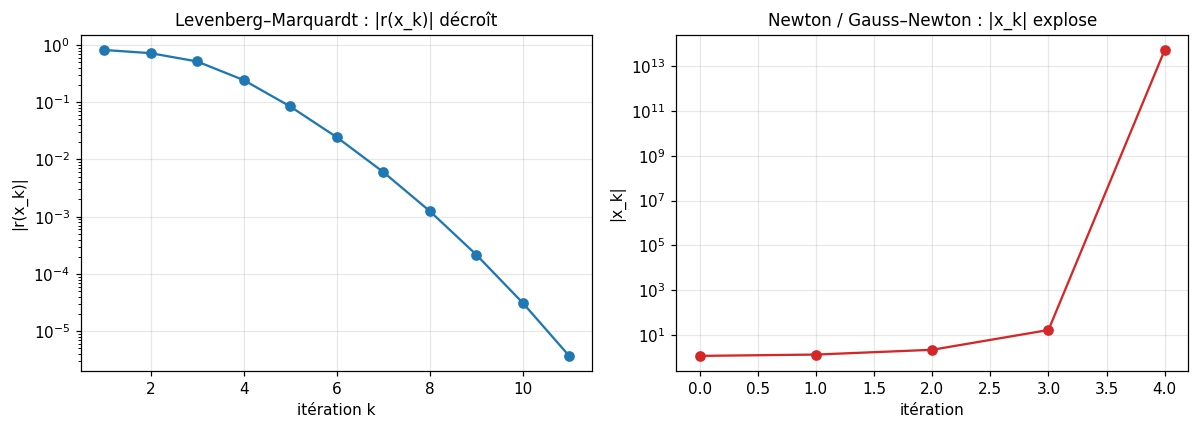

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(np.arange(1, len(errs) + 1), errs, "o-", color="C0")
ax[0].set(title="Levenberg–Marquardt : |r(x_k)| décroît", xlabel="itération k", ylabel="|r(x_k)|")
ax[1].semilogy(np.arange(len(xs_newton)), np.abs(xs_newton), "o-", color="C3")
ax[1].set(title="Newton / Gauss–Newton : |x_k| explose", xlabel="itération", ylabel="|x_k|")
plt.tight_layout(); plt.show()

## 4. Comprendre l'approximation

LM remplace les erreurs courbes par leur **tangente** : $r(x_k+\Delta x)\approx r_k+J_k\Delta x$. Ce n'est qu'une approximation de *ce que seront les erreurs* — pas de la solution. Elle sert à **choisir où aller** , tandis que la vraie fonction sert à **vérifier** que le point choisi est bon. Elle n'est bonne que près de $x_k$, avec un écart borné (formule de Taylor) par:
$$\|r(x_k+\Delta x)-(r_k+J_k\Delta x)\|\le\tfrac{L}{2}\|\Delta x\|^2 ,$$
où $L$ majore la variation de la jacobienne. Doubler le pas peut multiplier l'écart par quatre : c'est la raison mathématique de la pénalité $\tfrac\lambda2\|\Delta x\|^2$.

En x_k = 1.15 : tanh = 0.8178, pente = 0.3313
Petit pas (distance 0.15) : tangente 0.768, réalité 0.762, écart 0.006
Grand saut GN (distance 2.47) : tangente 0.000, réalité -0.866, écart 0.866


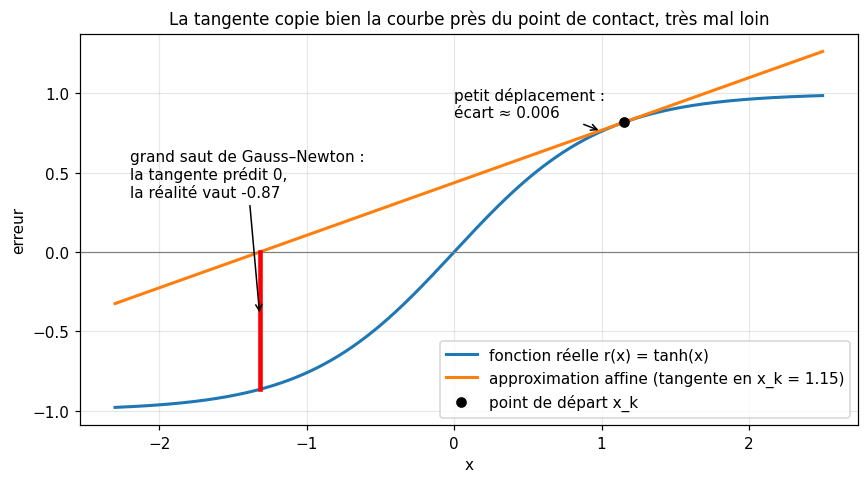

In [40]:
xk = 1.15
rk, Jk = np.tanh(xk), 1 - np.tanh(xk) ** 2
tangente = lambda x: rk + Jk * (x - xk)

# petit déplacement vers 1,0 et grand saut de Gauss–Newton
x_small, x_big = 1.0, xk - rk / Jk
gap_small, gap_big = abs(np.tanh(x_small) - tangente(x_small)), abs(np.tanh(x_big) - tangente(x_big))
print(f"En x_k = {xk} : tanh = {rk:.4f}, pente = {Jk:.4f}")
print(f"Petit pas (distance {abs(x_small - xk):.2f}) : tangente {tangente(x_small):.3f}, réalité {np.tanh(x_small):.3f}, écart {gap_small:.3f}")
print(f"Grand saut GN (distance {abs(x_big - xk):.2f}) : tangente {tangente(x_big):.3f}, réalité {np.tanh(x_big):.3f}, écart {gap_big:.3f}")

xx = np.linspace(-2.3, 2.5, 400)
plt.figure(figsize=(8, 4.5))
plt.plot(xx, np.tanh(xx), lw=2, label="fonction réelle r(x) = tanh(x)")
plt.plot(xx, tangente(xx), lw=2, label=f"approximation affine (tangente en x_k = {xk})")
plt.axhline(0, color="gray", lw=0.8)
plt.plot([xk], [rk], "ko", label="point de départ x_k")
plt.plot([x_big, x_big], [np.tanh(x_big), 0], "r-", lw=3)
plt.annotate(f"grand saut de Gauss–Newton :\nla tangente prédit 0,\nla réalité vaut {np.tanh(x_big):.2f}", (x_big, -0.4), (-2.2, 0.35), arrowprops=dict(arrowstyle="->"))
plt.annotate(f"petit déplacement :\nécart ≈ {gap_small:.3f}", (x_small, np.tanh(x_small)), (0.0, 0.85), arrowprops=dict(arrowstyle="->"))
plt.xlabel("x"); plt.ylabel("erreur"); plt.legend(loc="lower right"); plt.title("La tangente copie bien la courbe près du point de contact, très mal loin")
plt.tight_layout(); plt.show()

### Vérification de la borne

Pour $r=\tanh$, $|r''|\le L=\dfrac{4}{3\sqrt3}\approx0{,}77$. L'écart entre la tangente et la courbe doit donc rester sous $\tfrac L2\Delta x^2$ .

Borne respectée partout : True (L = 0.7698)


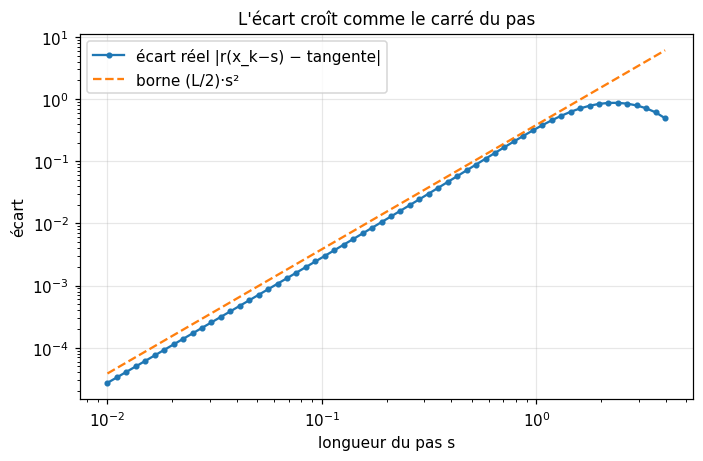

In [41]:
L = 4 / (3 * np.sqrt(3))
steps = np.logspace(-2, 0.6, 60)
gap = np.array([abs(np.tanh(xk - s) - tangente(xk - s)) for s in steps])
bound = 0.5 * L * steps ** 2
print("Borne respectée partout :", bool(np.all(gap <= bound + 1e-12)), f"(L = {L:.4f})")

plt.figure(figsize=(6.5, 4.3))
plt.loglog(steps, gap, "o-", ms=3, label="écart réel |r(x_k−s) − tangente|")
plt.loglog(steps, bound, "--", label="borne (L/2)·s²")
plt.xlabel("longueur du pas s"); plt.ylabel("écart"); plt.legend(); plt.title("L'écart croît comme le carré du pas")
plt.tight_layout(); plt.show()

### Le rôle de λ : longueur du pas selon λ

$\lambda\to0$ : Gauss–Newton (grand pas) ; $\lambda\to\infty$ : $\Delta x\approx-\tfrac1\lambda J^\top r$, petit pas de descente de gradient. On cherche le plus petit $\lambda$ pour lequel le pas est **accepté** (l'erreur réelle diminue).

Pas de Gauss–Newton (λ=0) : 2.47  -> accepté ? False
λ minimal pour lequel le pas est accepté : 0.0080
λ = 1 : pas de 0.24     λ = 100 : pas de 0.003


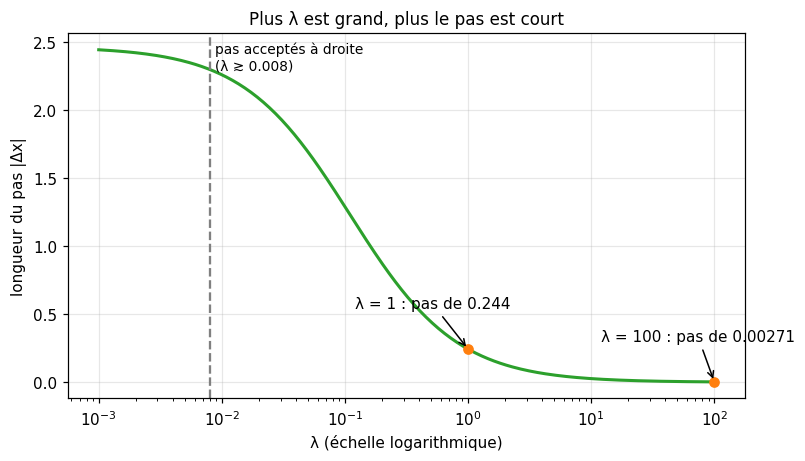

In [42]:
def step_1d(lam):
    return -Jk * rk / (lam + Jk ** 2)

lams = np.logspace(-3, 2, 300)
lens = np.abs(step_1d(lams))
accept = lambda lam: abs(np.tanh(xk + step_1d(lam))) - abs(rk)       # < 0 : erreur réelle diminue
lam_min = brentq(accept, 1e-4, 1.0)
print(f"Pas de Gauss–Newton (λ=0) : {abs(step_1d(0.0)):.2f}  -> accepté ? {accept(0.0) < 0}")
print(f"λ minimal pour lequel le pas est accepté : {lam_min:.4f}")
print(f"λ = 1 : pas de {abs(step_1d(1.0)):.2f}     λ = 100 : pas de {abs(step_1d(100.0)):.3f}")

plt.figure(figsize=(7.5, 4.3))
plt.semilogx(lams, lens, color="C2", lw=2)
plt.axvline(lam_min, color="gray", ls="--"); plt.text(lam_min * 1.1, 2.3, f"pas acceptés à droite\n(λ ≳ {lam_min:.3f})", fontsize=9)
for l in [1, 100]:
    plt.plot(l, abs(step_1d(l)), "o", color="C1"); plt.annotate(f"λ = {l} : pas de {abs(step_1d(l)):.3g}", (l, abs(step_1d(l))), (l * 0.12, abs(step_1d(l)) + 0.3), arrowprops=dict(arrowstyle="->"))
plt.xlabel("λ (échelle logarithmique)"); plt.ylabel("longueur du pas |Δx|"); plt.title("Plus λ est grand, plus le pas est court")
plt.tight_layout(); plt.show()

## 5. Piloter λ

Cas à **deux paramètres** : ajuster $y=a\,e^{bx}$ sur 30 points bruités depuis une initialisation volontairement mauvaise $(0{,}2\,;\,1{,}5)$ et un petit $\lambda_0=10^{-2}$. Le tableau affiche chaque tentative : $\lambda$, $\rho$ et la décision.


In [43]:
rng1 = np.random.default_rng(1)
xe = np.linspace(0, 4, 30)
noise1 = rng1.standard_normal(xe.size)
ye = 2.5 * np.exp(-0.7 * xe) + 0.05 * noise1

def res_exp(p):  return p[0] * np.exp(p[1] * xe) - ye                      # r_i = f(x_i) − y_i
def jac_exp(p):
    e = np.exp(p[1] * xe)
    return np.column_stack([e, p[0] * xe * e])                               # N × 2

p_start = np.array([0.2, 1.5])
print("Erreur jacobienne (différences finies) :", check_jacobian(res_exp, jac_exp, p_start))

print("\n--- Règle « gain » ---")
res_gain = levenberg_marquardt(res_exp, jac_exp, p_start, lam0=1e-2, rule="gain", verbose=True)
print("\n--- Règle « book » (0,8 / 2) ---")
res_book = levenberg_marquardt(res_exp, jac_exp, p_start, lam0=1e-2, rule="book")

for nom, o in [("gain", res_gain), ("book", res_book)]:
    print(f"{nom:>5} : solution {o.x}, coût {o.cost:.5f}, essais {o.n_iter} (rejetés {o.n_rejected}), arrêt : {o.status}")
print("Valeur vraie : [2.5, -0.7]")

Erreur jacobienne (différences finies) : 2.523375997043331e-08

--- Règle « gain » ---
 it     lambda      F essai      rho  decision
  0   1.00e-02  1.71828e+02    0.984  accepte
  1   3.33e-03  3.52753e+01    0.875  accepte
  2   1.11e-03  1.43940e+01    0.980  accepte
  3   3.70e-04  1.08993e+01    0.310  accepte
  4   3.70e-04  6.82944e+22 -7897051237950544674816.000  rejete
  5   1.48e-03  2.98732e+22 -3454674631312017981440.000  rejete
  6   5.93e-03  1.31919e+21 -152785428429559201792.000  rejete
  7   2.37e-02  5.53900e+16 -6525222046796352.000  rejete
  8   9.48e-02  4.45738e+07 -5818639.379  rejete
  9   3.79e-01  2.42039e-01    1.761  accepte
 10   1.26e-01  2.51100e-02    0.998  accepte
 11   4.21e-02  2.45559e-02    0.991  accepte
 12   1.40e-02  2.45558e-02    0.996  accepte
 13   4.68e-03  2.45558e-02    0.991  accepte
 14   1.56e-03  2.45558e-02    0.806  accepte

--- Règle « book » (0,8 / 2) ---
 gain : solution [ 2.5273 -0.7113], coût 0.02456, essais 15 (rejetés 5), a


 $\lambda$ **monte** quand un pas est rejeté (loin de l'optimum : prudence, comportement « gradient »), puis **redescend** quand la tangente devient fiable (comportement « Gauss–Newton »).

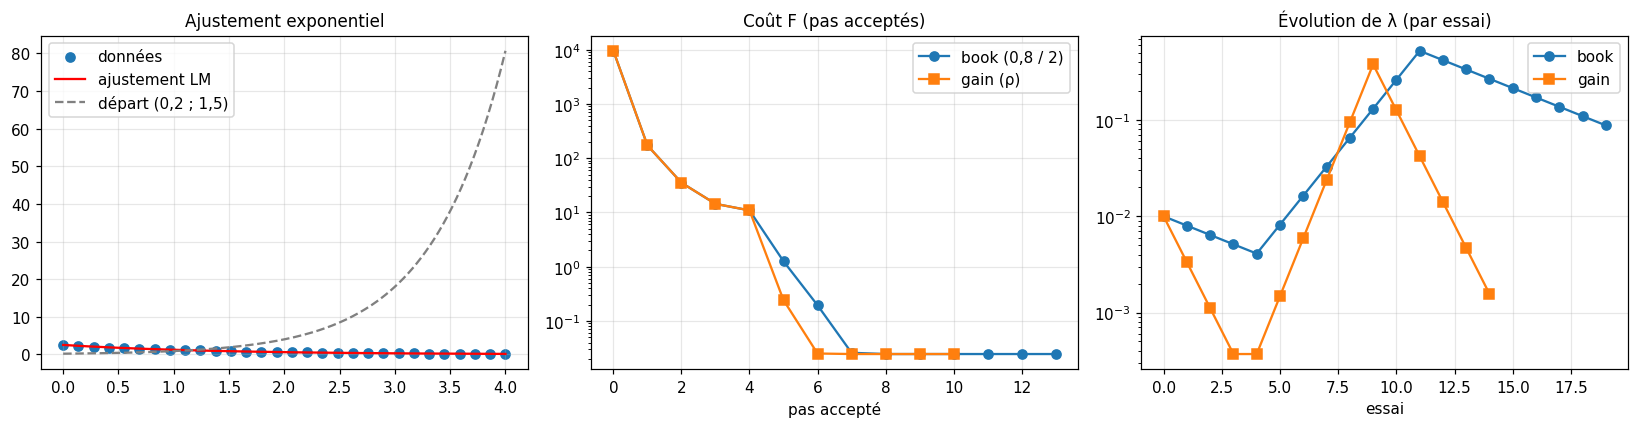

In [44]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(xe, ye, label="données"); xs = np.linspace(0, 4, 200)
ax[0].plot(xs, res_gain.x[0] * np.exp(res_gain.x[1] * xs), "r", label="ajustement LM")
ax[0].plot(xs, p_start[0] * np.exp(p_start[1] * xs), "--", color="gray", label="départ (0,2 ; 1,5)")
ax[0].set(title="Ajustement exponentiel"); ax[0].legend()
ax[1].semilogy(res_book.F_hist, "o-", label="book (0,8 / 2)"); ax[1].semilogy(res_gain.F_hist, "s-", label="gain (ρ)")
ax[1].set(title="Coût F (pas acceptés)", xlabel="pas accepté"); ax[1].legend()
ax[2].semilogy(res_book.lam_hist, "o-", label="book"); ax[2].semilogy(res_gain.lam_hist, "s-", label="gain")
ax[2].set(title="Évolution de λ (par essai)", xlabel="essai"); ax[2].legend()
plt.tight_layout(); plt.show()

## 6. Visualisation pas à pas sur un exemple à 2 paramètres

Trois points $(0,1),(1,2),(2,4)$, le modèle $f(x)=a\,e^{bx}$ et le départ $\theta_0=(1,0)$. On trace, dans l'ordre : le modèle et les résidus, le paysage du coût, le gradient, les trois types de pas (gradient, Gauss–Newton, LM), le rapport $\rho$, la trajectoire et la convergence. Le paysage montre $\log_{10}F(a,b)$ : plus c'est foncé, plus le coût est petit.

In [45]:
X3 = np.array([0, 1, 2.0]); Y3 = np.array([1, 2, 4.0])
res3 = lambda p: p[0] * np.exp(p[1] * X3) - Y3
jac3 = lambda p: np.column_stack([np.exp(p[1] * X3), p[0] * X3 * np.exp(p[1] * X3)])
F3 = lambda p: 0.5 * np.sum(res3(p) ** 2)
P0 = np.array([1.0, 0.0])

def essai(p, lam):
    """Pas LM (D = I) depuis p : (Δx, F(p+Δx), ρ)."""
    r, J = res3(p), jac3(p); d = lm_step(r, J, lam, solver="normal")
    Fn = F3(p + d); pred = F3(p) - 0.5 * np.sum((r + J @ d) ** 2)
    return d, Fn, (F3(p) - Fn) / pred

res_path = levenberg_marquardt(res3, jac3, P0, lam0=1.0, rule="book", tol_g=1e-9, max_iter=80)
path = np.array(res_path.x_hist); P_star = res_path.x
_, gnp, gnF = gauss_newton(res3, jac3, P0, max_iter=8)
_, gdh = gradient_descent(res3, jac3, P0, lr=0.02, max_iter=60)
print("Solution LM :", P_star, f"(vrai : a=1, b=ln2={np.log(2):.4f})  F = {F3(P_star):.2e}  en {res_path.n_iter} essais")

aa, bb = np.meshgrid(np.linspace(-0.5, 3, 300), np.linspace(-0.6, 1.9, 300))
Fgrid = np.array([[F3(np.array([a, b])) for a in aa[0]] for b in bb[:, 0]])
def paysage(ax):
    ax.contourf(aa, bb, np.log10(Fgrid + 0.02), levels=18, cmap="Blues_r")
    ax.set_xlabel("a"); ax.set_ylabel("b"); ax.plot(*P0, "o", color="C1", ms=8); ax.annotate("θ₀", P0, (6, 6), textcoords="offset points")

Solution LM : [1.     0.6931] (vrai : a=1, b=ln2=0.6931)  F = 1.58e-14  en 16 essais


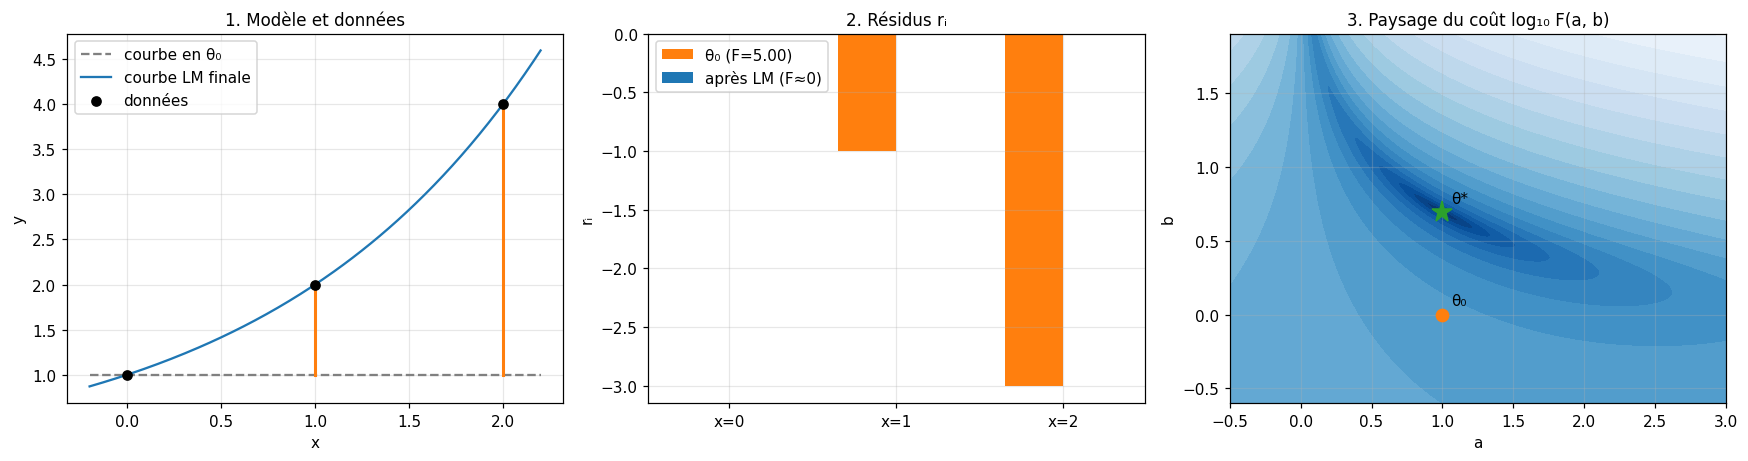

In [46]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
xs = np.linspace(-0.2, 2.2, 200)
ax[0].plot(xs, P0[0] * np.exp(P0[1] * xs), "--", color="gray", label="courbe en θ₀")
ax[0].plot(xs, P_star[0] * np.exp(P_star[1] * xs), color="C0", label="courbe LM finale")
for xi, yi in zip(X3, Y3):
    ax[0].plot([xi, xi], [yi, P0[0] * np.exp(P0[1] * xi)], color="C1", lw=2)
ax[0].scatter(X3, Y3, c="k", zorder=3, label="données"); ax[0].set(title="1. Modèle et données", xlabel="x", ylabel="y"); ax[0].legend()

w = 0.35; i = np.arange(3)
ax[1].bar(i - w / 2, res3(P0), w, color="C1", label=f"θ₀ (F={F3(P0):.2f})")
ax[1].bar(i + w / 2, res3(P_star), w, color="C0", label="après LM (F≈0)")
ax[1].set_xticks(i); ax[1].set_xticklabels([f"x={v:g}" for v in X3]); ax[1].set(title="2. Résidus rᵢ", ylabel="rᵢ"); ax[1].legend()

paysage(ax[2]); ax[2].plot(*P_star, "*", color="C2", ms=14); ax[2].annotate("θ*", P_star, (6, 6), textcoords="offset points")
ax[2].set_title("3. Paysage du coût log₁₀ F(a, b)")
plt.tight_layout(); plt.show()

### Jacobienne, gradient, et les trois types de pas

La courbe pointillée est l'ensemble des pas LM quand $\lambda$ varie de $10^{-4}$ à $10^{4}$ : elle part du pas de **Gauss–Newton** ($\lambda$ petit) et se replie vers $\theta_0$ en suivant $-g$ **(gradient)** quand $\lambda$ grandit. Le panneau de droite montre la norme du pas (qui décroît) et son angle avec $-g$ (qui tend vers 0 : pas de gradient).

r = [ 0. -1. -3.] 
J =
 [[1. 0.]
 [1. 1.]
 [1. 2.]] 
g = Jᵀr = [-4. -7.] 
JᵀJ =
 [[3. 3.]
 [3. 5.]] 
F = 5.0


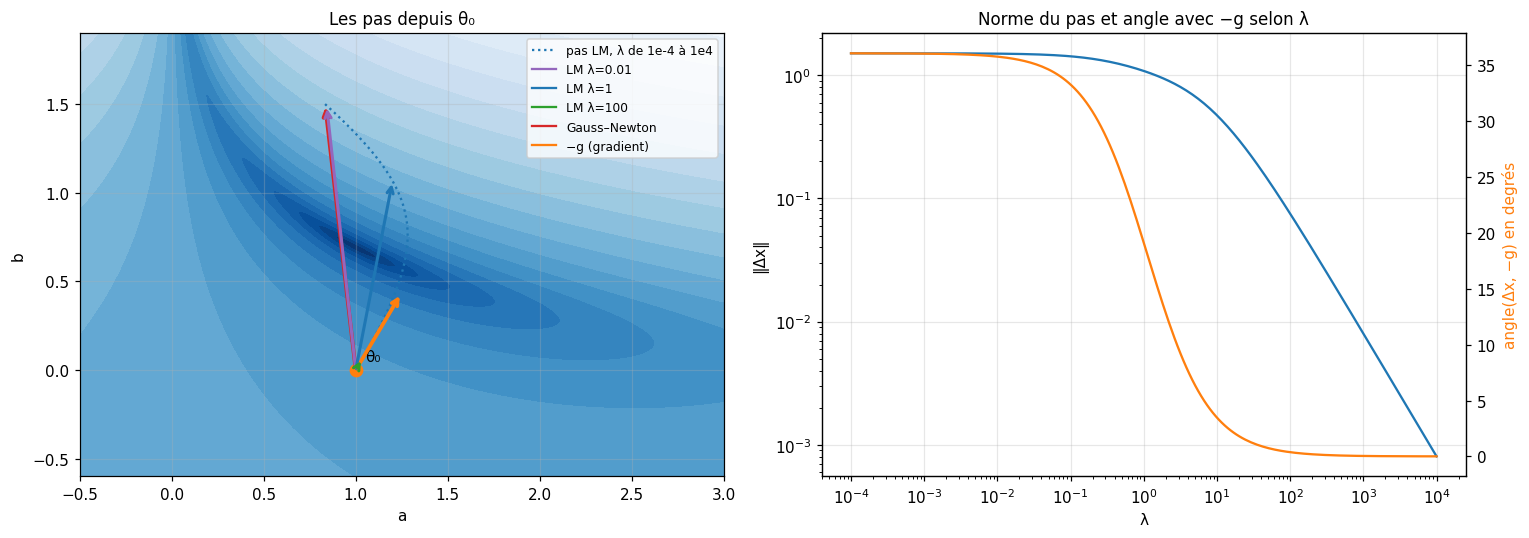

Gauss–Newton : θ₀+Δx = [0.8333 1.5   ]  F = 82.64620431100643


In [47]:
r0, J0 = res3(P0), jac3(P0); g0 = J0.T @ r0; A0 = J0.T @ J0
print("r =", r0, "\nJ =\n", J0, "\ng = Jᵀr =", g0, "\nJᵀJ =\n", A0, "\nF =", F3(P0))

d_gn = np.linalg.solve(A0, -g0)
lam_sweep = np.logspace(-4, 4, 200)
trace = np.array([P0 + essai(P0, l)[0] for l in lam_sweep])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
paysage(ax[0])
ax[0].plot(trace[:, 0], trace[:, 1], ":", color="C0", lw=1.5, label="pas LM, λ de 1e-4 à 1e4")
ax[0].annotate("", xy=P0 - 0.5 * g0 / np.linalg.norm(g0), xytext=P0, arrowprops=dict(arrowstyle="->", color="C1", lw=2.5))
ax[0].annotate("", xy=P0 + d_gn, xytext=P0, arrowprops=dict(arrowstyle="->", color="C3", lw=2.5))
for l, c in [(0.01, "C4"), (1, "C0"), (100, "C2")]:
    ax[0].annotate("", xy=P0 + essai(P0, l)[0], xytext=P0, arrowprops=dict(arrowstyle="->", color=c, lw=2)); ax[0].plot([], [], color=c, label=f"LM λ={l:g}")
ax[0].plot([], [], color="C3", label="Gauss–Newton"); ax[0].plot([], [], color="C1", label="−g (gradient)")
ax[0].set_xlim(-0.5, 3); ax[0].set_ylim(-0.6, 1.9); ax[0].legend(fontsize=8); ax[0].set_title("Les pas depuis θ₀")

norms = [np.linalg.norm(essai(P0, l)[0]) for l in lam_sweep]
ang = [np.degrees(np.arccos(np.clip(essai(P0, l)[0] @ -g0 / (np.linalg.norm(essai(P0, l)[0]) * np.linalg.norm(g0)), -1, 1))) for l in lam_sweep]
ax[1].loglog(lam_sweep, norms, color="C0"); ax[1].set(xlabel="λ", ylabel="‖Δx‖", title="Norme du pas et angle avec −g selon λ")
ax2 = ax[1].twinx(); ax2.semilogx(lam_sweep, ang, color="C1"); ax2.set_ylabel("angle(Δx, −g) en degrés", color="C1"); ax2.grid(False)
plt.tight_layout(); plt.show()
print("Gauss–Newton : θ₀+Δx =", P0 + d_gn, " F =", F3(P0 + d_gn))

### Accepter ou rejeter : le rapport ρ, puis trajectoire et convergence

$\rho>0$ : l'erreur réelle diminue (pas accepté). Pour $\lambda$ trop petit, $\rho<0$ : la tangente nous a trompés. La trajectoire compare LM (régulière), Gauss–Newton pur (saut initial très loin) et la descente de gradient (lente).

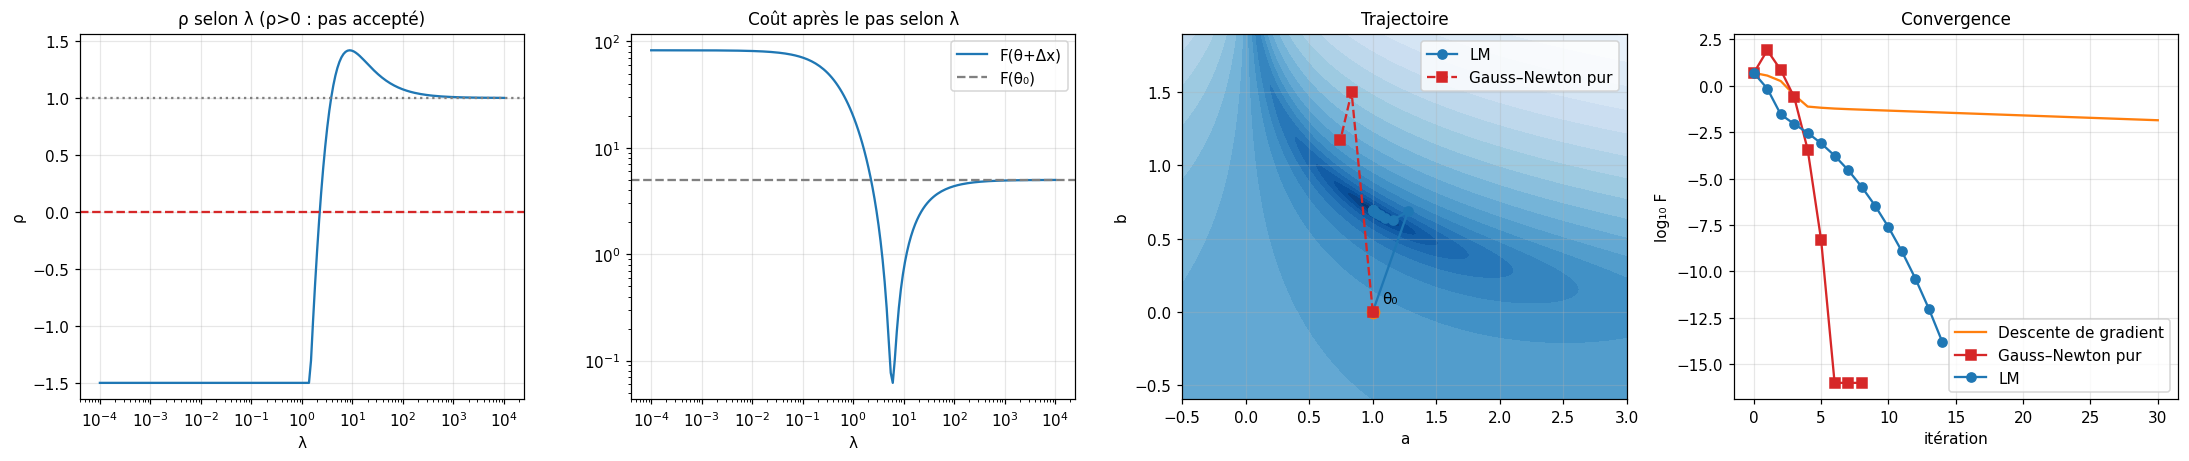

  k     lambda       rho      F essai  décision
  0  1.000e+00    -3.160   1.9923e+01  rejeté
  1  2.000e+00    -0.345   6.5497e+00  rejeté
  2  4.000e+00     1.059   7.1267e-01  accepté
  3  3.200e+00     0.993   2.8962e-02  accepté
  4  2.560e+00     0.999   8.7807e-03  accepté
  5  2.048e+00     1.000   2.9448e-03  accepté
  6  1.638e+00     1.000   8.0252e-04  accepté
  7  1.311e+00     1.000   1.7387e-04  accepté
  8  1.049e+00     1.000   2.9261e-05  accepté
  9  8.389e-01     1.000   3.7373e-06  accepté


In [48]:
rho_v, Fn_v = [], []
for l in lam_sweep:
    _, Fn, rho = essai(P0, l); rho_v.append(rho); Fn_v.append(Fn)

fig, ax = plt.subplots(1, 4, figsize=(20, 4.3))
ax[0].semilogx(lam_sweep, np.clip(rho_v, -1.5, 1.8)); ax[0].axhline(0, color="C3", ls="--"); ax[0].axhline(1, color="gray", ls=":")
ax[0].set(title="ρ selon λ (ρ>0 : pas accepté)", xlabel="λ", ylabel="ρ")
ax[1].loglog(lam_sweep, Fn_v, label="F(θ+Δx)"); ax[1].axhline(F3(P0), color="gray", ls="--", label="F(θ₀)")
ax[1].set(title="Coût après le pas selon λ", xlabel="λ"); ax[1].legend()

paysage(ax[2])
ax[2].plot(path[:, 0], path[:, 1], "o-", color="C0", label="LM"); ax[2].plot(gnp[:3, 0], gnp[:3, 1], "s--", color="C3", label="Gauss–Newton pur")
ax[2].set_xlim(-0.5, 3); ax[2].set_ylim(-0.6, 1.9); ax[2].legend(); ax[2].set_title("Trajectoire")

lg = lambda v: np.log10(np.maximum(v, 1e-16))
ax[3].plot(lg(gdh[:31]), color="C1", label="Descente de gradient")
ax[3].plot(lg(gnF), "s-", color="C3", label="Gauss–Newton pur")
ax[3].plot(lg(res_path.F_hist), "o-", color="C0", label="LM")
ax[3].set(title="Convergence", xlabel="itération", ylabel="log₁₀ F"); ax[3].legend()
plt.tight_layout(); plt.show()

print(f"{'k':>3} {'lambda':>10} {'rho':>9} {'F essai':>12}  décision")
for t in res_path.trials[:10]:
    print(f"{t['k']:>3} {t['lam']:>10.3e} {t['rho']:>9.3f} {t['F_try']:>12.4e}  {'accepté' if t['ok'] else 'rejeté'}")

## 7. Conditions et vitesse de convergence

### 7.1 Garanties à chaque itération
On vérifie numériquement, sur les exécutions de la section 5 : le pas est **toujours** une direction de descente ($g^\top\Delta x<0$) ; $F$ **décroît strictement** à chaque pas accepté ; la boucle de rejets **s'arrête** (on trouve toujours un $\lambda$ assez grand).

In [50]:
for nom, o in [("book (éq. 11)", res_book), ("gain (éq. 12)", res_gain), ("pas à pas §6", res_path)]:
    gdx = np.array([t["gdx"] for t in o.trials])
    F_h = np.array(o.F_hist)
    run = best_run = 0                      # plus longue série de rejets consécutifs
    for t in o.trials:
        run = 0 if t["ok"] else run + 1; best_run = max(best_run, run)
    print(f"[{nom:<14}] (ii) gᵀΔx < 0 aux {len(gdx)} essais : {bool(np.all(gdx < 0))}  |  (iv) F strictement décroissant : "
          f"{bool(np.all(np.diff(F_h) < 0))}  |  (iii) rejets : {o.n_rejected}, max consécutifs : {best_run}, puis un pas accepté")

[book (éq. 11) ] (ii) gᵀΔx < 0 aux 20 essais : True  |  (iv) F strictement décroissant : True  |  (iii) rejets : 7, max consécutifs : 7, puis un pas accepté
[gain (éq. 12) ] (ii) gᵀΔx < 0 aux 15 essais : True  |  (iv) F strictement décroissant : True  |  (iii) rejets : 5, max consécutifs : 5, puis un pas accepté
[pas à pas §6  ] (ii) gᵀΔx < 0 aux 16 essais : True  |  (iv) F strictement décroissant : True  |  (iii) rejets : 2, max consécutifs : 2, puis un pas accepté


### 7.2 Vitesse de convergence près de la solution


σ = 0.0   : essais = 13  coût final = 1.470e-27  ‖g‖∞ = 8.6e-14  arrêt : gradient
σ = 0.05  : essais = 71  coût final = 2.456e-02  ‖g‖∞ = 2.3e-12  arrêt : lambda
σ = 0.3   : essais = 70  coût final = 8.857e-01  ‖g‖∞ = 2.6e-12  arrêt : lambda
σ=0, λ_k = ‖r_k‖ : erreurs ['1.7e+00', '9.8e-01', '3.7e-01', '7.1e-02', '3.1e-03', '6.5e-06', '2.8e-11', '1.0e-17']
   rapports e_{k+1}/e_k² (bornés ⇒ ordre 2) : ['0.36', '0.39', '0.51', '0.62', '0.66', '0.66']

σ=0, règle book : erreurs successives ['1.7e+00', '7.4e-01', '1.8e-01', '3.3e-02', '5.2e-03', '6.7e-04', '7.1e-05', '6.2e-06', '4.4e-07', '2.5e-08', '1.2e-09', '4.4e-11']
σ=0, règle gain : erreurs successives ['1.7e+00', '7.4e-01', '1.1e-01', '4.1e-03', '5.4e-05', '2.4e-07', '3.6e-10', '1.8e-13', '5.0e-16']


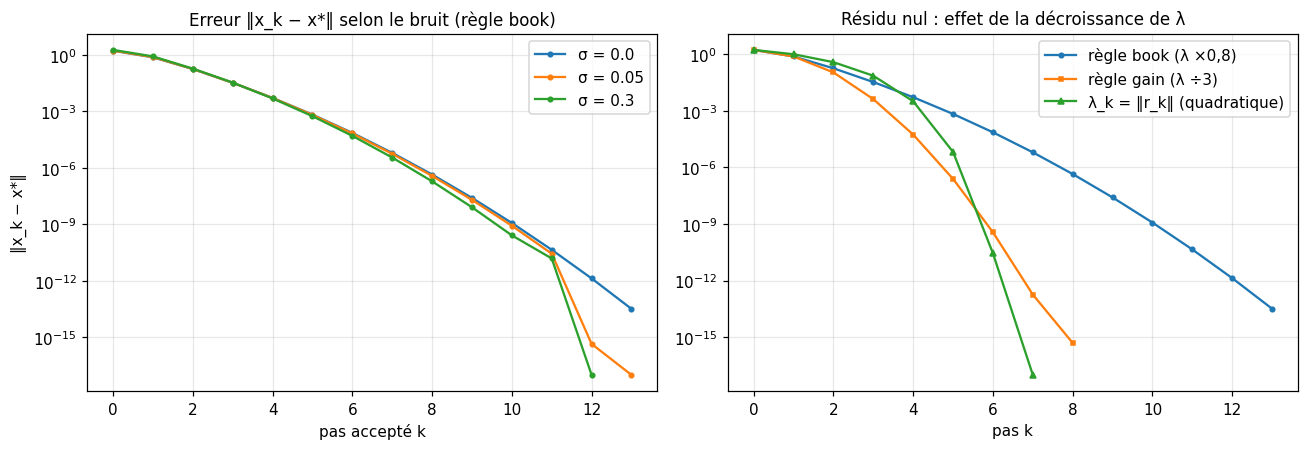

In [51]:
def fit_sigma(sig, rule="book", lam0=1.0):
    y = 2.5 * np.exp(-0.7 * xe) + sig * noise1
    rs = lambda p: p[0] * np.exp(p[1] * xe) - y
    # solution « de référence » à haute précision
    ref = levenberg_marquardt(rs, jac_exp, [1.0, 0.0], lam0=1.0, tol_g=1e-14, tol_r=0, max_iter=500)
    o = levenberg_marquardt(rs, jac_exp, [1.0, 0.0], lam0=lam0, rule=rule, tol_g=1e-13, tol_r=1e-30, max_iter=80)
    err = np.array([np.linalg.norm(xh - ref.x) for xh in o.x_hist])
    return o, np.maximum(err, 1e-17), np.linalg.norm(jac_exp(o.x).T @ rs(o.x), np.inf)

curves = {}
for sig in [0.0, 0.05, 0.3]:
    o, err, gn_ = fit_sigma(sig)
    curves[sig] = err
    print(f"σ = {sig:<5} : essais = {o.n_iter:<3d} coût final = {o.cost:.3e}  ‖g‖∞ = {gn_:.1e}  arrêt : {o.status}")
o_gain0, err_gain0, _ = fit_sigma(0.0, rule="gain")

# Variante classique (Yamashita & Fukushima, 2001) : λ_k = ‖r_k‖ tend vers 0 avec le résidu => convergence quadratique
y0 = 2.5 * np.exp(-0.7 * xe); rs0 = lambda p: p[0] * np.exp(p[1] * xe) - y0
x_loc = np.array([1.0, 0.0]); x_star0 = np.array([2.5, -0.7]); err_yf = [np.linalg.norm(x_loc - x_star0)]
for _ in range(7):
    r_ = rs0(x_loc)
    x_loc = x_loc + lm_step(r_, jac_exp(x_loc), np.linalg.norm(r_), solver="normal")   # λ_k = ‖r_k‖
    err_yf.append(max(np.linalg.norm(x_loc - x_star0), 1e-17))
err_yf = np.array(err_yf)
print("σ=0, λ_k = ‖r_k‖ : erreurs", ["%.1e" % v for v in err_yf])
print("   rapports e_{k+1}/e_k² (bornés ⇒ ordre 2) :", ["%.2f" % (err_yf[i + 1] / err_yf[i] ** 2) for i in range(len(err_yf) - 1) if err_yf[i] > 1e-7])

e = curves[0.0]; ratios = e[1:] / e[:-1]
print("\nσ=0, règle book : erreurs successives", ["%.1e" % v for v in e[:12]])
print("σ=0, règle gain : erreurs successives", ["%.1e" % v for v in err_gain0[:12]])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for sig, err in curves.items():
    ax[0].semilogy(err, "o-", ms=3, label=f"σ = {sig}")
ax[0].set(title="Erreur ‖x_k − x*‖ selon le bruit (règle book)", xlabel="pas accepté k", ylabel="‖x_k − x*‖"); ax[0].legend()
ax[1].semilogy(curves[0.0], "o-", ms=3, label="règle book (λ ×0,8)"); ax[1].semilogy(err_gain0, "s-", ms=3, label="règle gain (λ ÷3)")
ax[1].semilogy(err_yf, "^-", ms=4, label="λ_k = ‖r_k‖ (quadratique)")
ax[1].set(title="Résidu nul : effet de la décroissance de λ", xlabel="pas k"); ax[1].legend()
plt.tight_layout(); plt.show()

## 8. Complexité temporelle et spatiale  

Une itération coûte $C_J+C_r+2(m+n)n^2$ , le terme dominant étant la résolution du système. On le mesure :

- **A** : $m$ fixé, $n$ variable : le temps de la QR empilée doit croître en $n^2$ (puis $n^3$ si $n\gtrsim m$) ;
- **B** : $n$ fixé, $m$ variable : croissance **linéaire** en $m$ ;
- **C** : *kernel trick* pour $m\ll n$ : $2nm^2$ au lieu de $2(m+n)n^2$ ;
- **D** : précision : $\mathrm{cond}(J^\top J)=\mathrm{cond}(J)^2$, donc les équations normales perdent la moitié des chiffres exacts par rapport à la QR.

Mémoire : $J$ occupe $O(mn)$, $J^\top J+\lambda I$ occupe $O(n^2)$, la matrice empilée $O((m+n)n)$.

A. pente log-log en n  : QR 1.72   normales 2.21   (théorie : 2 à 3)
B. pente log-log en m  : QR 0.66   normales 0.90   (théorie : 1)
   rapport de temps QR / normales à m = 25600 : 18×
C. gain du kernel trick à n=1600 : 1343× plus rapide que la QR empilée

Mémoire (m=2000, n=1280) : J = 20.5 Mo ; JᵀJ = 13.1 Mo ; matrice empilée = 33.6 Mo


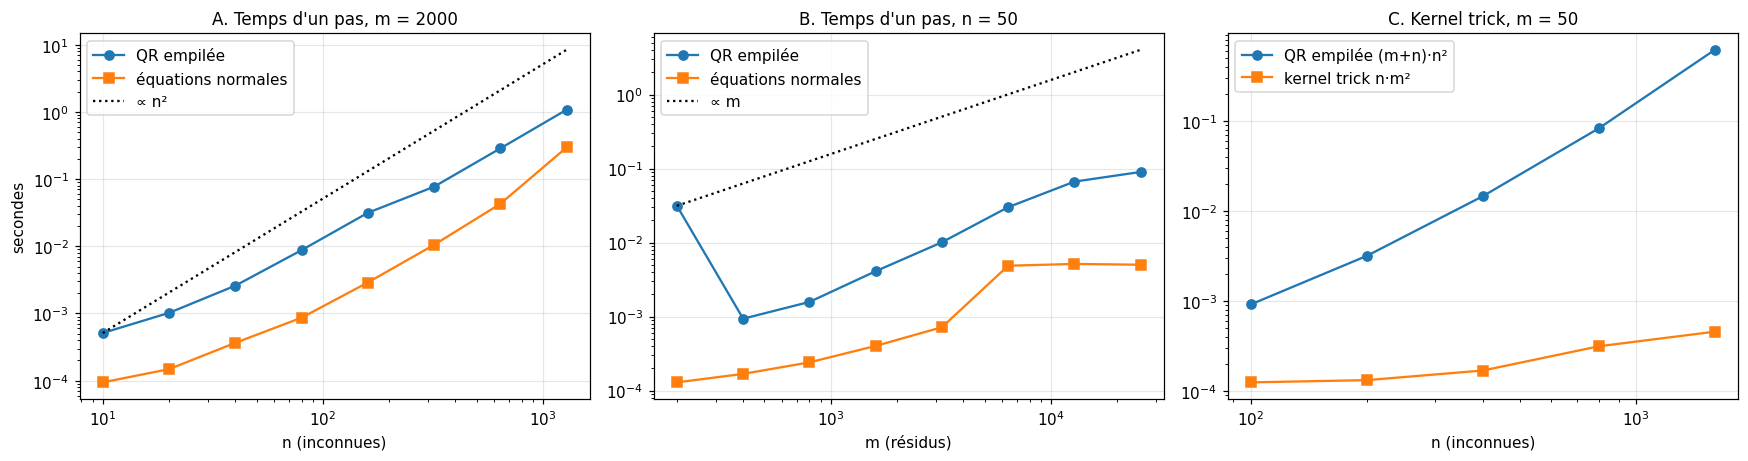

In [52]:
def best_time(f, rep=5):
    ts = []
    for _ in range(rep):
        t0 = time.perf_counter(); f(); ts.append(time.perf_counter() - t0)
    return min(ts)

rngc = np.random.default_rng(0)

# A. m fixé, n variable
m_fix = 2000; ns = [10, 20, 40, 80, 160, 320, 640, 1280]
tA_qr, tA_ne = [], []
for n in ns:
    Jc, rc_ = rngc.standard_normal((m_fix, n)), rngc.standard_normal(m_fix)
    tA_qr.append(best_time(lambda: lm_step(rc_, Jc, 1e-2, solver="qr")))
    tA_ne.append(best_time(lambda: lm_step(rc_, Jc, 1e-2, solver="normal")))

# B. n fixé, m variable
n_fix = 50; ms = [200, 400, 800, 1600, 3200, 6400, 12800, 25600]
tB_qr, tB_ne = [], []
for m_ in ms:
    Jc, rc_ = rngc.standard_normal((m_, n_fix)), rngc.standard_normal(m_)
    tB_qr.append(best_time(lambda: lm_step(rc_, Jc, 1e-2, solver="qr")))
    tB_ne.append(best_time(lambda: lm_step(rc_, Jc, 1e-2, solver="normal")))

# C. kernel trick (m << n)
m_k = 50; nk = [100, 200, 400, 800, 1600]
tC_qr, tC_kern = [], []
for n in nk:
    Jc, rc_ = rngc.standard_normal((m_k, n)), rngc.standard_normal(m_k)
    tC_qr.append(best_time(lambda: lm_step(rc_, Jc, 1e-2, solver="qr"), rep=3))
    tC_kern.append(best_time(lambda: -Jc.T @ np.linalg.solve(Jc @ Jc.T + 1e-2 * np.eye(m_k), rc_), rep=3))

slope = lambda x, t, k=4: np.polyfit(np.log(x[-k:]), np.log(t[-k:]), 1)[0]
print(f"A. pente log-log en n  : QR {slope(ns, tA_qr):.2f}   normales {slope(ns, tA_ne):.2f}   (théorie : 2 à 3)")
print(f"B. pente log-log en m  : QR {slope(ms, tB_qr, len(ms)):.2f}   normales {slope(ms, tB_ne, len(ms)):.2f}   (théorie : 1)")
print(f"   rapport de temps QR / normales à m = {ms[-1]} : {tB_qr[-1] / tB_ne[-1]:.0f}×")
print(f"C. gain du kernel trick à n={nk[-1]} : {tC_qr[-1] / tC_kern[-1]:.0f}× plus rapide que la QR empilée")
print(f"\nMémoire (m={m_fix}, n=1280) : J = {m_fix*1280*8/1e6:.1f} Mo ; JᵀJ = {1280*1280*8/1e6:.1f} Mo ; matrice empilée = {(m_fix+1280)*1280*8/1e6:.1f} Mo")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].loglog(ns, tA_qr, "o-", label="QR empilée"); ax[0].loglog(ns, tA_ne, "s-", label="équations normales")
ax[0].loglog(ns, tA_qr[0] * (np.array(ns) / ns[0]) ** 2, "k:", label="∝ n²")
ax[0].set(title=f"A. Temps d'un pas, m = {m_fix}", xlabel="n (inconnues)", ylabel="secondes"); ax[0].legend()
ax[1].loglog(ms, tB_qr, "o-", label="QR empilée"); ax[1].loglog(ms, tB_ne, "s-", label="équations normales")
ax[1].loglog(ms, tB_qr[0] * (np.array(ms) / ms[0]), "k:", label="∝ m")
ax[1].set(title=f"B. Temps d'un pas, n = {n_fix}", xlabel="m (résidus)"); ax[1].legend()
ax[2].loglog(nk, tC_qr, "o-", label="QR empilée (m+n)·n²"); ax[2].loglog(nk, tC_kern, "s-", label="kernel trick n·m²")
ax[2].set(title=f"C. Kernel trick, m = {m_k}", xlabel="n (inconnues)"); ax[2].legend()
plt.tight_layout(); plt.show()

In [53]:
# D. précision : normales (cond au carré) contre QR empilée, contre une référence SVD
rngd = np.random.default_rng(1)
m_, n_ = 60, 8
U, _ = np.linalg.qr(rngd.standard_normal((m_, n_))); V, _ = np.linalg.qr(rngd.standard_normal((n_, n_)))
s = np.logspace(0, -7, n_); Jc = U @ np.diag(s) @ V.T; rc_ = rngd.standard_normal(m_)
print(f"cond(J) = {np.linalg.cond(Jc):.1e}   cond(JᵀJ) = {np.linalg.cond(Jc.T @ Jc):.1e}\n")
print(f"{'λ':>8} {'cond(JᵀJ+λI)':>15} {'erreur relative normales':>26} {'erreur relative QR':>20}")
for lam in [1e-2, 1e-8, 1e-12]:
    d_ref = -V @ ((s / (s ** 2 + lam)) * (U.T @ rc_))                # référence stable (SVD)
    d_ne, d_qr = lm_step(rc_, Jc, lam, solver="normal"), lm_step(rc_, Jc, lam, solver="qr")
    cnd = np.linalg.cond(Jc.T @ Jc + lam * np.eye(n_))
    print(f"{lam:>8.0e} {cnd:>15.1e} {np.linalg.norm(d_ne - d_ref) / np.linalg.norm(d_ref):>26.1e} {np.linalg.norm(d_qr - d_ref) / np.linalg.norm(d_ref):>20.1e}")

cond(J) = 1.0e+07   cond(JᵀJ) = 1.0e+14

       λ    cond(JᵀJ+λI)   erreur relative normales   erreur relative QR
   1e-02         1.0e+02                    1.0e-14              1.7e-15
   1e-08         1.0e+08                    1.3e-09              3.9e-12
   1e-12         9.9e+11                    1.5e-05              7.8e-11


## 9. Cas d'usage typiques  

### 9.1 Localisation à partir de mesures de distance (trilatération)
Cinq repères $a_i$ connus, des distances $\rho_i$ mesurées (bruitées) vers un point inconnu de vraie position $(1,1)$. Résidu : $r_i(x)=\|x-a_i\|-\rho_i$. La jacobienne a pour ligne $\dfrac{(x-a_i)^\top}{\|x-a_i\|}$. Le paysage possède **plusieurs vallées** : selon le départ, LM atteint le meilleur point ou un minimum local non optimal.

In [54]:
A_lm = np.array([[1.8, 2.5], [2.0, 1.7], [1.5, 1.5], [1.5, 2.0], [2.5, 1.5]])
x_true = np.array([1.0, 1.0])
rho_m = np.linalg.norm(A_lm - x_true, axis=1) + 0.2 * np.random.default_rng(3).uniform(-1, 1, 5)

r_loc = lambda x: np.linalg.norm(x - A_lm, axis=1) - rho_m
def J_loc(x):
    d = x - A_lm
    return d / np.maximum(np.linalg.norm(d, axis=1), 1e-12)[:, None]    # (non définie exactement sur un repère)
print("Erreur jacobienne :", check_jacobian(r_loc, J_loc, np.array([0.3, 0.7])))

starts = [(1.8, 3.5), (3.0, 1.5), (-1, -1), (0, 0), (3, 3), (2.5, 0), (0, 3), (-2, 2)]
print(f"\n{'départ':>12} {'point atteint':>18} {'‖r‖²':>8} {'essais':>7}")
runs_loc = []
for x0 in starts:
    o = levenberg_marquardt(r_loc, J_loc, x0, lam0=0.1, max_iter=200)
    runs_loc.append(o)
    print(f"{str(x0):>12} {str(np.round(o.x, 3)):>18} {2 * o.cost:>8.4f} {o.n_iter:>7d}")
best = min(runs_loc, key=lambda o: o.cost).x
local = max(runs_loc, key=lambda o: o.cost).x
print("\nMeilleur point :", np.round(best, 3), " | minimum local :", np.round(local, 3), " | vérité :", x_true)

Erreur jacobienne : 1.8380152955188578e-10

      départ      point atteint     ‖r‖²  essais
  (1.8, 3.5)      [2.771 2.384]   1.1114      13
  (3.0, 1.5)      [2.771 2.384]   1.1114      12
    (-1, -1)      [1.187 0.917]   0.0552      16
      (0, 0)      [1.187 0.917]   0.0552      16
      (3, 3)      [2.771 2.384]   1.1114      11
    (2.5, 0)      [1.187 0.917]   0.0552      16
      (0, 3)      [1.187 0.917]   0.0552      18
     (-2, 2)      [1.187 0.917]   0.0552      18

Meilleur point : [1.187 0.917]  | minimum local : [2.771 2.384]  | vérité : [1. 1.]


Part des départs menant au meilleur point : 81% | au minimum local : 19% | ailleurs : 0%


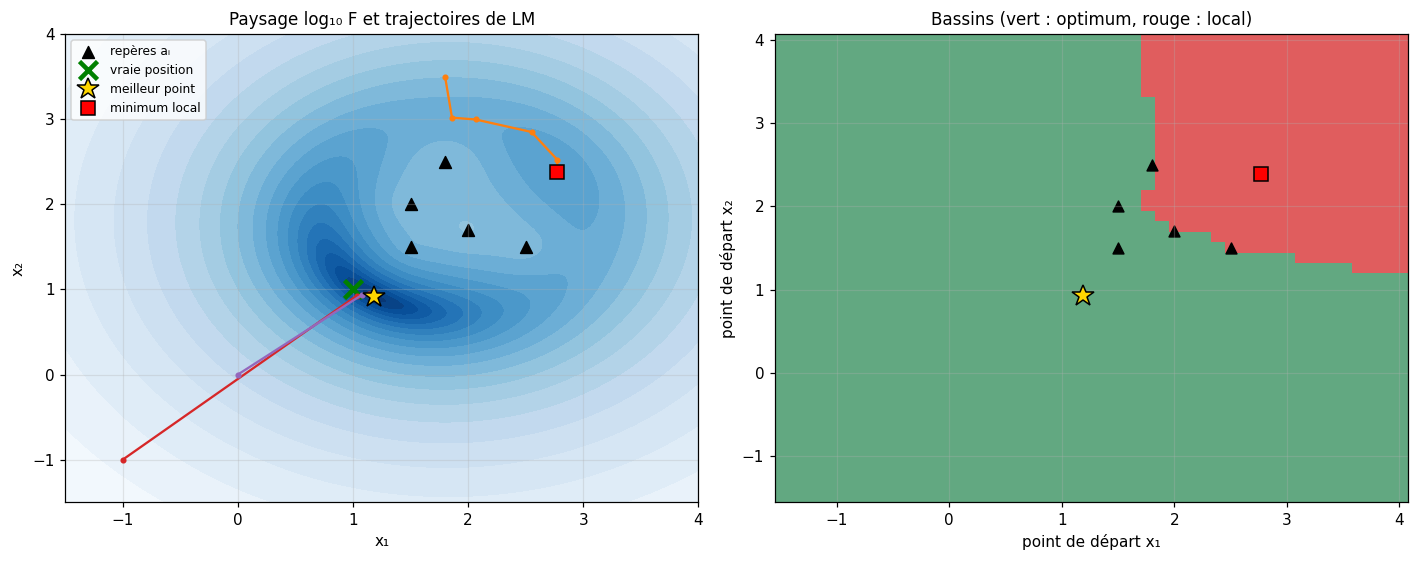

In [55]:
# Carte des bassins d'attraction : où LM aboutit-il selon le point de départ ?
# grille légèrement décalée : la jacobienne n'est pas définie exactement sur un repère (‖x − aᵢ‖ = 0)
gx = np.linspace(-1.5, 4.0, 45) + 0.0137; gy = np.linspace(-1.5, 4.0, 45) + 0.0071
basin = np.zeros((gy.size, gx.size), dtype=int)
for iy, yy in enumerate(gy):
    for ix, xx_ in enumerate(gx):
        o = levenberg_marquardt(r_loc, J_loc, [xx_, yy], lam0=0.1, max_iter=100)
        basin[iy, ix] = 0 if np.linalg.norm(o.x - best) < 0.05 else (1 if np.linalg.norm(o.x - local) < 0.05 else 2)
print("Part des départs menant au meilleur point :", f"{np.mean(basin == 0):.0%}", "| au minimum local :", f"{np.mean(basin == 1):.0%}", "| ailleurs :", f"{np.mean(basin == 2):.0%}")

gxx, gyy = np.meshgrid(np.linspace(-1.5, 4.0, 200), np.linspace(-1.5, 4.0, 200))
Fgrid_loc = np.array([[0.5 * np.sum(r_loc(np.array([a, b])) ** 2) for a in gxx[0]] for b in gyy[:, 0]])
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
cs = ax[0].contourf(gxx, gyy, np.log10(Fgrid_loc + 1e-3), levels=20, cmap="Blues_r")
ax[0].scatter(*A_lm.T, marker="^", c="k", s=60, label="repères aᵢ"); ax[0].plot(*x_true, "gx", ms=12, mew=3, label="vraie position")
for o, c in zip([runs_loc[0], runs_loc[2], runs_loc[3]], ["C1", "C3", "C4"]):
    P = np.array(o.x_hist); ax[0].plot(P[:, 0], P[:, 1], "o-", ms=3, color=c)
ax[0].plot(*best, "*", ms=15, color="gold", mec="k", label="meilleur point"); ax[0].plot(*local, "s", ms=9, color="red", mec="k", label="minimum local")
ax[0].legend(fontsize=8, loc="upper left"); ax[0].set_title("Paysage log₁₀ F et trajectoires de LM"); ax[0].set_xlabel("x₁"); ax[0].set_ylabel("x₂")
from matplotlib.colors import ListedColormap
ax[1].pcolormesh(gx, gy, basin, cmap=ListedColormap(["#2e8b57", "#d62728", "#999999"]), shading="nearest", vmin=0, vmax=2, alpha=0.75)
ax[1].scatter(*A_lm.T, marker="^", c="k", s=50); ax[1].plot(*best, "*", ms=15, color="gold", mec="k"); ax[1].plot(*local, "s", ms=9, color="red", mec="k")
ax[1].set_title("Bassins (vert : optimum, rouge : local)"); ax[1].set_xlabel("point de départ x₁"); ax[1].set_ylabel("point de départ x₂")
plt.tight_layout(); plt.show()

### 9.2 Prix d'équilibre
Deux biens, offre $S(p)$ et demande $D(p)$ à élasticités constantes (exponentielles de logarithmes). Résidu : l'**excès d'offre** $r(p)=S(p)-D(p)$ ; l'équilibre est le point où $r(p)=0$ (système de 2 équations, 2 inconnues : $m=n=2$, départ $p=(3,9)$ et $\lambda_1=1$)

Erreur jacobienne : 9.73301883533395e-10
départ    (3, 9) : p* = [2.1096 2.0248]  ‖r‖² : 71.5 → 3.1e-13  en 8 essais (rejetés : 0)
départ (0.5, 0.5) : p* = [2.1096 2.0248]  ‖r‖² : 79.7 → 3.8e-13  en 8 essais (rejetés : 0)
départ   (10, 1) : p* = [2.1096 2.0248]  ‖r‖² : 194.5 → 2.5e-13  en 8 essais (rejetés : 0)


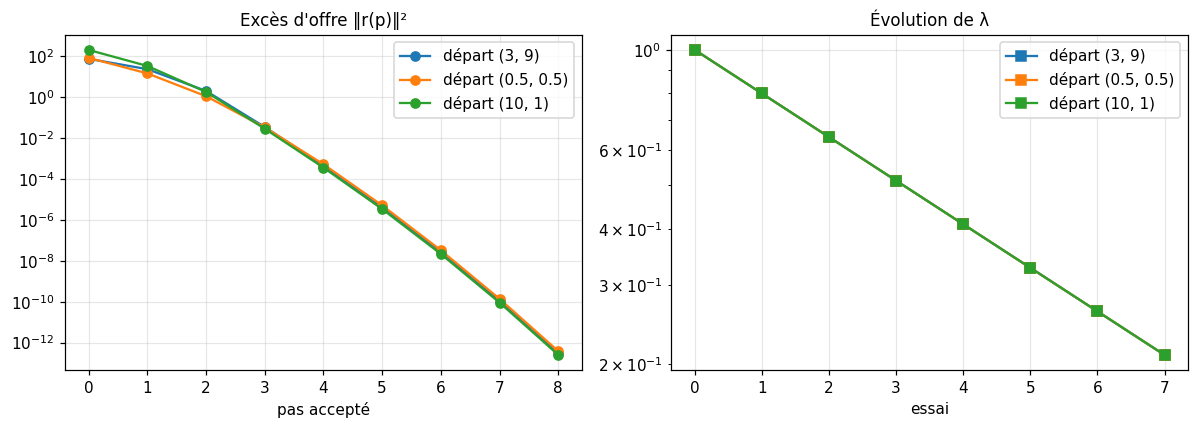

In [56]:
s0, d0 = np.array([2.0, 3.0]), np.array([5.0, 6.0])
E_s = np.array([[0.8, -0.2], [-0.1, 0.6]])        # élasticités de l'offre
E_d = np.array([[-0.9, 0.3], [0.2, -0.7]])        # élasticités de la demande
S = lambda p: s0 * np.exp(E_s @ np.log(p))
D = lambda p: d0 * np.exp(E_d @ np.log(p))
r_eq = lambda p: S(p) - D(p)
J_eq = lambda p: (S(p)[:, None] * E_s - D(p)[:, None] * E_d) / p[None, :]
print("Erreur jacobienne :", check_jacobian(r_eq, J_eq, np.array([3.0, 9.0])))

runs_eq = {}
for start in [(3, 9), (0.5, 0.5), (10, 1)]:
    o = levenberg_marquardt(r_eq, J_eq, np.array(start, float), lam0=1.0)
    runs_eq[start] = o
    print(f"départ {str(start):>9} : p* = {np.round(o.x, 4)}  ‖r‖² : {2 * o.F_hist[0]:.1f} → {2 * o.cost:.1e}  en {o.n_iter} essais (rejetés : {o.n_rejected})")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for st, o in runs_eq.items():
    ax[0].semilogy(2 * np.array(o.F_hist), "o-", label=f"départ {st}"); ax[1].semilogy(o.lam_hist, "s-", label=f"départ {st}")
ax[0].set(title="Excès d'offre ‖r(p)‖²", xlabel="pas accepté"); ax[0].legend(); ax[1].set(title="Évolution de λ", xlabel="essai"); ax[1].legend()
plt.tight_layout(); plt.show()

### 9.3 Ajustement non linéaire : sinusoïde amortie
Modèle $\hat f(x;\theta)=\theta_1e^{\theta_2x}\cos(\theta_3x+\theta_4)$ (amplitude, amortissement, fréquence, phase) ajusté à $N=60$ points bruités. Les inconnues sont les 4 paramètres ; $J$ est de taille $60\times4$. On compare LM *from scratch*, `scipy.optimize.least_squares(method="lm")`, Gauss–Newton pur et la descente de gradient.

In [57]:
N_s = 60
xs_s = np.linspace(0, 6, N_s)
th_true = np.array([1.5, -0.35, 3.0, 0.6])
f_s = lambda th, x: th[0] * np.exp(th[1] * x) * np.cos(th[2] * x + th[3])
y_s = f_s(th_true, xs_s) + 0.05 * np.random.default_rng(5).standard_normal(N_s)
r_s = lambda th: f_s(th, xs_s) - y_s
def J_s(th):
    e, c, sn = np.exp(th[1] * xs_s), np.cos(th[2] * xs_s + th[3]), np.sin(th[2] * xs_s + th[3])
    return np.column_stack([e * c, th[0] * xs_s * e * c, -th[0] * e * xs_s * sn, -th[0] * e * sn])
print("Erreur jacobienne :", check_jacobian(r_s, J_s, np.array([1.0, -0.1, 2.7, 0.0])))

def compare(th0, lr=2e-3):
    out = []
    t = time.perf_counter(); o = levenberg_marquardt(r_s, J_s, th0, lam0=1.0, max_iter=300); out.append(("LM (from scratch)", o.x, o.cost, o.n_iter, o.nfev, time.perf_counter() - t))
    t = time.perf_counter(); sp = least_squares(r_s, th0, jac=J_s, method="lm"); out.append(("scipy least_squares (lm)", sp.x, sp.cost, sp.nfev, sp.nfev, time.perf_counter() - t))
    t = time.perf_counter(); xg, _, Fg = gauss_newton(r_s, J_s, th0, max_iter=50); out.append(("Gauss–Newton pur", xg, Fg[-1], len(Fg) - 1, len(Fg), time.perf_counter() - t))
    t = time.perf_counter(); xd, hd = gradient_descent(r_s, J_s, th0, lr=lr, max_iter=2000); out.append(("Descente de gradient", xd, hd[-1], len(hd), len(hd), time.perf_counter() - t))
    return out, o

for nom, th0 in [("départ proche (1, −0,1, 2,7, 0)", np.array([1.0, -0.1, 2.7, 0.0])), ("départ éloigné (1, 0, 5, 0)", np.array([1.0, 0.0, 5.0, 0.0]))]:
    tab, o_lm = compare(th0)
    print(f"\n=== {nom} ===")
    print(f"{'Méthode':<26}{'coût final':>11}{'itérations':>12}{'éval. r':>9}{'temps (s)':>11}   θ final")
    for n_, x_, c_, it_, nf_, tt_ in tab:
        print(f"{n_:<26}{c_:>11.4f}{it_:>12}{nf_:>9}{tt_:>11.4f}   {np.round(x_, 3) if np.all(np.isfinite(x_)) and np.max(np.abs(x_)) < 1e6 else 'diverge'}")
    if "proche" in nom: o_near = o_lm
    else: o_far = o_lm
print("\nVraie valeur :", th_true)

Erreur jacobienne : 6.824327769550109e-10

=== départ proche (1, −0,1, 2,7, 0) ===
Méthode                    coût final  itérations  éval. r  temps (s)   θ final
LM (from scratch)              0.0651          11       12     0.0075   [ 1.441 -0.331  3.001  0.594]
scipy least_squares (lm)       0.0651           9        9     0.0016   [ 1.441 -0.331  3.001  0.594]
Gauss–Newton pur               0.0651          14       15     0.0017   [ 1.441 -0.331  3.001  0.594]
Descente de gradient           0.0651        2000     2000     0.0779   [ 1.441 -0.331  3.001  0.594]

=== départ éloigné (1, 0, 5, 0) ===
Méthode                    coût final  itérations  éval. r  temps (s)   θ final
LM (from scratch)              0.0651          18       19     0.0036   [ 1.441 -0.331  3.001  0.594]
scipy least_squares (lm)       0.0651          13       13     0.0011   [ 1.441 -0.331  3.001  0.594]
Gauss–Newton pur               6.5585          50       51     0.0056   [ 7185.663 -2241.918 -6513.869  1050

Départs aléatoires : 40/40 atteignent le meilleur minimum (coût 0.0651) ; coût médian 0.0651, max 0.065


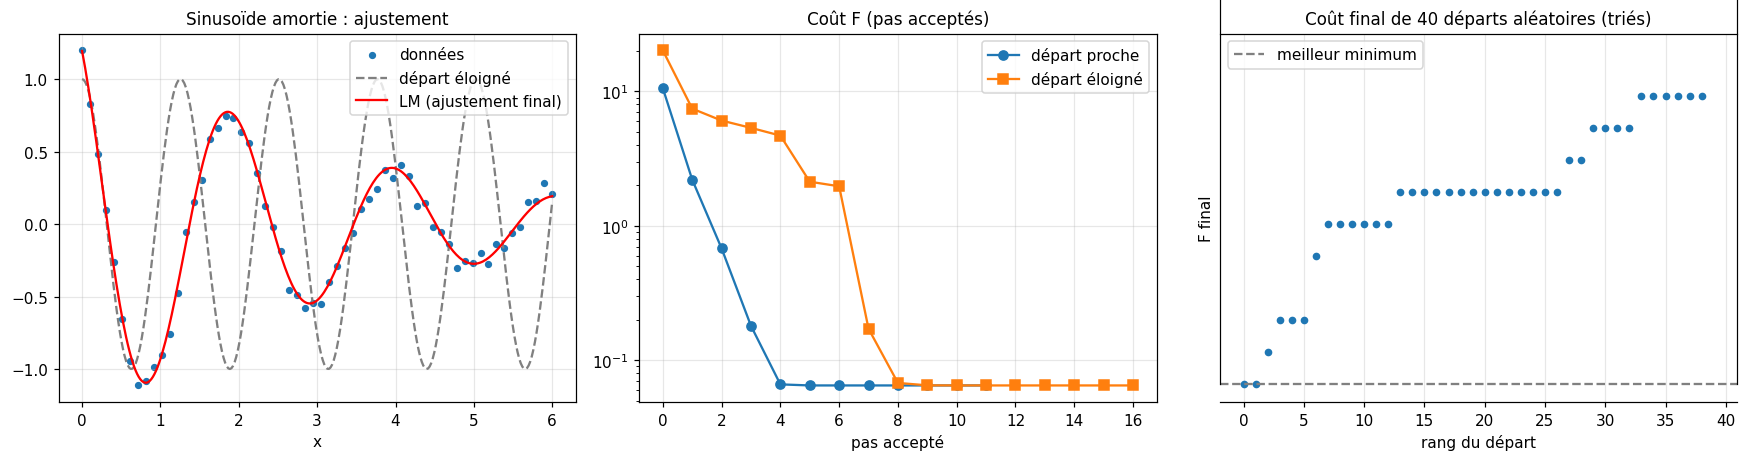

In [58]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
xx = np.linspace(0, 6, 300)
ax[0].scatter(xs_s, y_s, s=14, label="données")
ax[0].plot(xx, f_s(np.array([1.0, 0.0, 5.0, 0.0]), xx), "--", color="gray", label="départ éloigné")
ax[0].plot(xx, f_s(o_far.x, xx), "r", label="LM (ajustement final)")
ax[0].set(title="Sinusoïde amortie : ajustement", xlabel="x"); ax[0].legend()
ax[1].semilogy(o_near.F_hist, "o-", label="départ proche"); ax[1].semilogy(o_far.F_hist, "s-", label="départ éloigné")
ax[1].set(title="Coût F (pas acceptés)", xlabel="pas accepté"); ax[1].legend()

# robustesse : 40 départs aléatoires (fréquence dans [1, 8])
rng_s = np.random.default_rng(11); final_costs = []
for _ in range(40):
    th0 = np.array([rng_s.uniform(0.5, 2.5), rng_s.uniform(-1, 0.3), rng_s.uniform(1, 8), rng_s.uniform(-1.5, 1.5)])
    final_costs.append(levenberg_marquardt(r_s, J_s, th0, lam0=1.0, max_iter=300).cost)
final_costs = np.array(final_costs); c_best = final_costs.min()
n_ok = int(np.sum(final_costs < 1.05 * c_best))
print(f"Départs aléatoires : {n_ok}/40 atteignent le meilleur minimum (coût {c_best:.4f}) ; coût médian {np.median(final_costs):.4f}, max {final_costs.max():.3f}")
ax[2].semilogy(np.sort(final_costs), "o", ms=4); ax[2].axhline(c_best, color="gray", ls="--", label="meilleur minimum")
ax[2].set(title="Coût final de 40 départs aléatoires (triés)", xlabel="rang du départ", ylabel="F final"); ax[2].legend()
plt.tight_layout(); plt.show()

### 9.4 Séries de problèmes proches : démarrage à chaud (*warm start*)
On ajuste le même modèle avec une régularisation $\mu\|\theta\|^2$ pour plusieurs valeurs décroissantes de $\mu$ (résidus augmentés $\bigl(r,\ \sqrt\mu\,\theta\bigr)$, jacobienne $\binom{J}{\sqrt\mu\,I}$). On compare un départ **à froid** (même point initial à chaque fois) et **à chaud** (solution du problème précédent). Si les problèmes sont proches, le nombre d'itérations chute.

      μ   à froid   à chaud
     10        12        12
      3        18        10
      1        23        12
    0.3        18        10
    0.1        14         8
   0.03        13         7
   0.01        17         7
  0.003        17         7
Total des itérations : à froid = 132, à chaud = 73  (gain ×1.8)


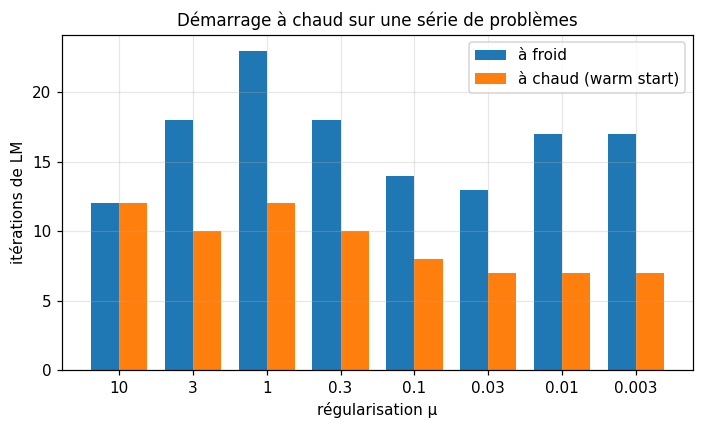

In [59]:
def make_reg(mu):
    r_ = lambda th: np.concatenate([r_s(th), np.sqrt(mu) * th])
    J_ = lambda th: np.vstack([J_s(th), np.sqrt(mu) * np.eye(4)])
    return r_, J_

mus = [10.0, 3.0, 1.0, 0.3, 0.1, 0.03, 0.01, 0.003]
th_cold0 = np.array([1.0, 0.0, 5.0, 0.0])
it_cold, it_warm, th_prev = [], [], th_cold0.copy()
for mu in mus:
    r_, J_ = make_reg(mu)
    it_cold.append(levenberg_marquardt(r_, J_, th_cold0, lam0=1.0, max_iter=300, tol_g=1e-7).n_iter)
    ow = levenberg_marquardt(r_, J_, th_prev, lam0=1.0, max_iter=300, tol_g=1e-7)
    it_warm.append(ow.n_iter); th_prev = ow.x
print(f"{'μ':>7} {'à froid':>9} {'à chaud':>9}")
for mu, a, b in zip(mus, it_cold, it_warm):
    print(f"{mu:>7g} {a:>9d} {b:>9d}")
print(f"Total des itérations : à froid = {sum(it_cold)}, à chaud = {sum(it_warm)}  (gain ×{sum(it_cold) / sum(it_warm):.1f})")

plt.figure(figsize=(6.5, 4))
w = 0.38; pos = np.arange(len(mus))
plt.bar(pos - w / 2, it_cold, w, label="à froid"); plt.bar(pos + w / 2, it_warm, w, label="à chaud (warm start)")
plt.xticks(pos, [f"{m:g}" for m in mus]); plt.xlabel("régularisation μ"); plt.ylabel("itérations de LM"); plt.title("Démarrage à chaud sur une série de problèmes"); plt.legend()
plt.tight_layout(); plt.show()

## 10. Application : régression avec un petit réseau 1 → H → 1

Entraîner un réseau par moindres carrés est un problème où LM est naturel : les inconnues sont les poids $\theta=[W_1\,(H),\ b_1\,(H),\ W_2\,(H),\ b_2\,(1)]$, donc $n=3H+1$ ; les résidus sont $r_i=\hat y(x_i)-y_i$ ; il y a **un résidu par exemple** ($m=N$).

- Sortie : $\hat y(x)=\sum_j W_{2,j}\tanh(W_{1,j}x+b_{1,j})+b_2$
- Jacobienne (ligne $i$), avec $h_j=\tanh(W_{1,j}x_i+b_{1,j})$ :
  $\partial r/\partial W_{1,j}=W_{2,j}(1-h_j^2)x_i$, $\ \partial r/\partial b_{1,j}=W_{2,j}(1-h_j^2)$, $\ \partial r/\partial W_{2,j}=h_j$, $\ \partial r/\partial b_2=1$.

C'est ce que calcule la rétropropagation, mais **exemple par exemple** (une ligne par point) au lieu d'une somme.

Données : $y=\sin(x)+\sigma\varepsilon$ avec $\sigma=0{,}05$ (variance du bruit $\sigma^2=0{,}0025$), 200 points, découpage 70 % apprentissage / 30 % test.

**Comment mesurer la vitesse ?** Sur des données bruitées la vallée est très plate : le coût continue à baisser très lentement bien après l'ajustement utile, donc « nombre d'itérations jusqu'à l'arrêt » dépend surtout du critère d'arrêt. On utilise donc une mesure indépendante de ce critère : le **nombre d'évaluations de $r$ nécessaires pour atteindre une MSE d'apprentissage cible**

In [60]:
def make_net(H, x, y):
    def unpack(p):
        return p[:H], p[H:2 * H], p[2 * H:3 * H], p[3 * H]
    def forward(p, xx):
        W1, b1, W2, b2 = unpack(p)
        h = np.tanh(np.outer(xx, W1) + b1)
        return h @ W2 + b2, h
    def residuals(p):
        return forward(p, x)[0] - y
    def jacobian(p):
        W1, b1, W2, b2 = unpack(p)
        _, h = forward(p, x)
        dh = W2 * (1 - h ** 2)
        return np.hstack([dh * x[:, None], dh, h, np.ones((x.size, 1))])
    return forward, residuals, jacobian, 3 * H + 1

rng_d = np.random.default_rng(0)
SIGMA = 0.05
x_all = np.linspace(-3, 3, 200)
y_all = np.sin(x_all) + SIGMA * rng_d.standard_normal(x_all.size)
idx = rng_d.permutation(x_all.size)
tr, te = idx[:140], idx[140:]
x_tr, y_tr, x_te, y_te = x_all[tr], y_all[tr], x_all[te], y_all[te]

H = 8
forward, residuals, jacobian, n_params = make_net(H, x_tr, y_tr)
p_init = 0.5 * np.random.default_rng(1).standard_normal(n_params)
mse_tr = lambda p: np.mean(residuals(p) ** 2)
mse_te = lambda p: np.mean((forward(p, x_te)[0] - y_te) ** 2)
m_tr = x_tr.size

MSE_CIBLE = 0.0022
def mse_curve(costs):
    # MSE d'apprentissage (meilleure valeur atteinte) après chaque évaluation de r
    return 2 * np.minimum.accumulate(np.asarray(costs)) / m_tr
def evals_to_target(costs):
    w = np.where(mse_curve(costs) <= MSE_CIBLE)[0]
    return int(w[0]) if w.size else None                       # None : cible jamais atteinte
lm_costs = lambda o: [o.F_hist[0]] + [t["F_try"] for t in o.trials]   # F après chaque évaluation de r

print(f"n = {n_params} paramètres, m = {m_tr} résidus d'apprentissage")
print("Erreur jacobienne du réseau :", check_jacobian(residuals, jacobian, p_init))

n = 25 paramètres, m = 140 résidus d'apprentissage
Erreur jacobienne du réseau : 3.5126164086782263e-10


### Expérience 1 — LM contre `scipy` contre descente de gradient
On compare l'**erreur** (MSE d'apprentissage et de test) et la **vitesse** (évaluations de $r$ pour atteindre la MSE cible, temps total). LM est testé avec les deux règles de $\lambda$ ; toutes les méthodes disposent d'un **budget fixe** (LM : 300 itérations sans arrêt anticipé, descente de gradient : 2000 itérations, scipy : ses critères par défaut) afin de comparer à budget égal sans dépendre d'un critère d'arrêt.

Méthode                    MSE train  MSE test  Éval. r  Éval. → cible  Temps (s)
LM from scratch (book)       0.00200   0.00226      301             59     0.1029
LM from scratch (gain)       0.00199   0.00225      301             69     0.0971
scipy least_squares (lm)     0.00205   0.00223     2500             18     0.6261
Descente de gradient         0.01821   0.01635     2000         > 2000     0.1815

Cible MSE = 0.0022 ; plancher théorique du bruit σ² = 0.00250 ; scipy : statut 0 (0 = nombre max d'évaluations atteint)


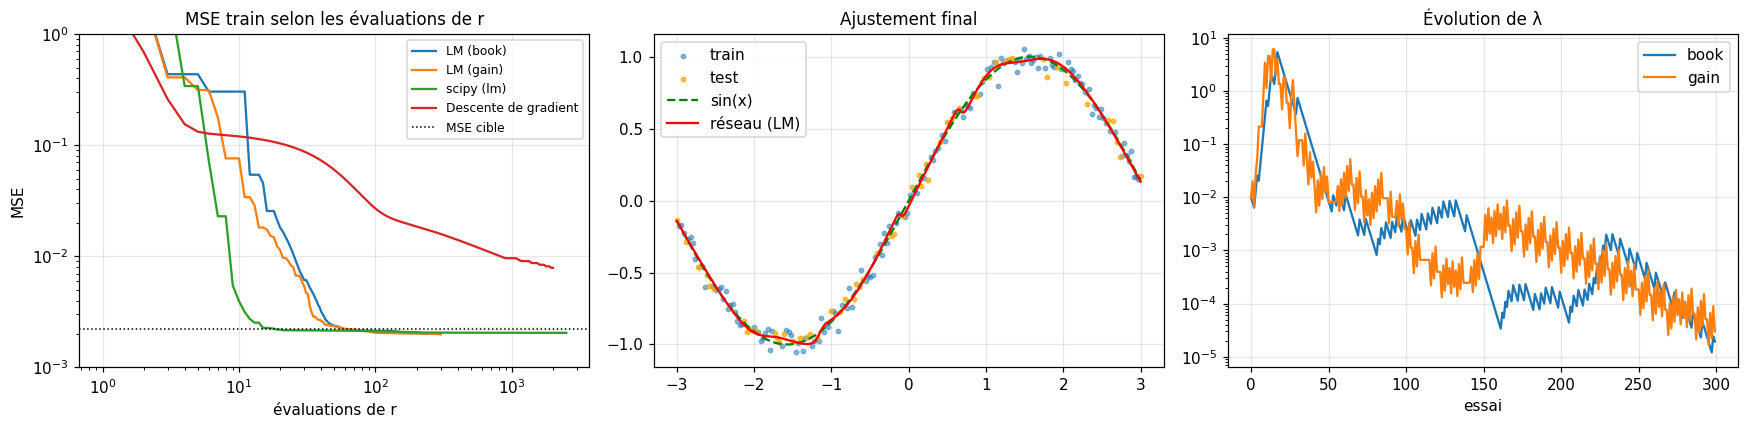

In [61]:
kw = dict(lam0=1e-2, max_iter=300, tol_f=0)
t = time.perf_counter(); o_book_nn = levenberg_marquardt(residuals, jacobian, p_init, rule="book", **kw); t_book = time.perf_counter() - t
t = time.perf_counter(); o_gain_nn = levenberg_marquardt(residuals, jacobian, p_init, rule="gain", **kw); t_gain = time.perf_counter() - t

sp_costs = []
def residuals_logged(p):
    r = residuals(p); sp_costs.append(0.5 * r @ r); return r
t = time.perf_counter(); sol = least_squares(residuals_logged, p_init, jac=jacobian, method="lm"); t_sp = time.perf_counter() - t
t = time.perf_counter(); p_gd, h_gd = gradient_descent(residuals, jacobian, p_init, lr=2e-3, max_iter=2000); t_gd = time.perf_counter() - t

rows = [
    ("LM from scratch (book)", mse_tr(o_book_nn.x), mse_te(o_book_nn.x), o_book_nn.nfev, evals_to_target(lm_costs(o_book_nn)), t_book),
    ("LM from scratch (gain)", mse_tr(o_gain_nn.x), mse_te(o_gain_nn.x), o_gain_nn.nfev, evals_to_target(lm_costs(o_gain_nn)), t_gain),
    ("scipy least_squares (lm)", mse_tr(sol.x), mse_te(sol.x), sol.nfev, evals_to_target(sp_costs), t_sp),
    ("Descente de gradient", mse_tr(p_gd), mse_te(p_gd), len(h_gd), evals_to_target(h_gd), t_gd),
]
print(f"{'Méthode':<26}{'MSE train':>10}{'MSE test':>10}{'Éval. r':>9}{'Éval. → cible':>15}{'Temps (s)':>11}")
for n_, a, b, nf, et, tt in rows:
    print(f"{n_:<26}{a:>10.5f}{b:>10.5f}{nf:>9}{('> ' + str(nf)) if et is None else et:>15}{tt:>11.4f}")
print(f"\nCible MSE = {MSE_CIBLE} ; plancher théorique du bruit σ² = {SIGMA ** 2:.5f} ; scipy : statut {sol.status} (0 = nombre max d'évaluations atteint)")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for nom, costs in [("LM (book)", lm_costs(o_book_nn)), ("LM (gain)", lm_costs(o_gain_nn)), ("scipy (lm)", sp_costs), ("Descente de gradient", h_gd)]:
    ax[0].loglog(np.arange(1, len(costs) + 1), mse_curve(costs), label=nom)
ax[0].axhline(MSE_CIBLE, color="k", ls=":", lw=1, label="MSE cible"); ax[0].set_ylim(1e-3, 1.0)
ax[0].set(title="MSE train selon les évaluations de r", xlabel="évaluations de r", ylabel="MSE"); ax[0].legend(fontsize=8)
xs = np.linspace(-3, 3, 400)
ax[1].scatter(x_tr, y_tr, s=8, alpha=.5, label="train"); ax[1].scatter(x_te, y_te, s=8, alpha=.7, color="orange", label="test")
ax[1].plot(xs, np.sin(xs), "g--", label="sin(x)"); ax[1].plot(xs, forward(o_book_nn.x, xs)[0], "r", label="réseau (LM)")
ax[1].set(title="Ajustement final"); ax[1].legend()
ax[2].semilogy(o_book_nn.lam_hist, label="book"); ax[2].semilogy(o_gain_nn.lam_hist, label="gain"); ax[2].set(title="Évolution de λ", xlabel="essai"); ax[2].legend()
plt.tight_layout(); plt.show()

### Expériences 2 et 3 — influence de $\lambda_0$ et du nombre de neurones $H$
Le $\lambda_0$ initial n'a d'effet que sur le **début** (un $\lambda_0$ trop petit provoque des rejets, un trop grand ralentit les premiers pas), car $\lambda$ s'adapte ensuite. $H$ règle la capacité du modèle : trop petit, sous-apprentissage ; trop grand, coût en $n^2$–$n^3$ et risque de surapprentissage.

Influence de λ₀ (règle book) :
  λ₀=1e-06    MSE=0.00210  évaluations totales=301  évaluations → cible=95  pas rejetés=78
  λ₀=0.01     MSE=0.00200  évaluations totales=301  évaluations → cible=59  pas rejetés=66
  λ₀=1        MSE=0.00219  évaluations totales=301  évaluations → cible=254  pas rejetés=66
  λ₀=100      MSE=0.00220  évaluations totales=301  évaluations → cible=None  pas rejetés=63

Influence de H (moyenne de 5 initialisations) :
  H=2   n=7    MSE train=0.02732  MSE test=0.02211  temps=0.0248s
  H=4   n=13   MSE train=0.00227  MSE test=0.00218  temps=0.0583s
  H=8   n=25   MSE train=0.00199  MSE test=0.00234  temps=0.1617s
  H=16  n=49   MSE train=0.00185  MSE test=0.00247  temps=0.3350s
  H=32  n=97   MSE train=0.00173  MSE test=0.00254  temps=0.9912s


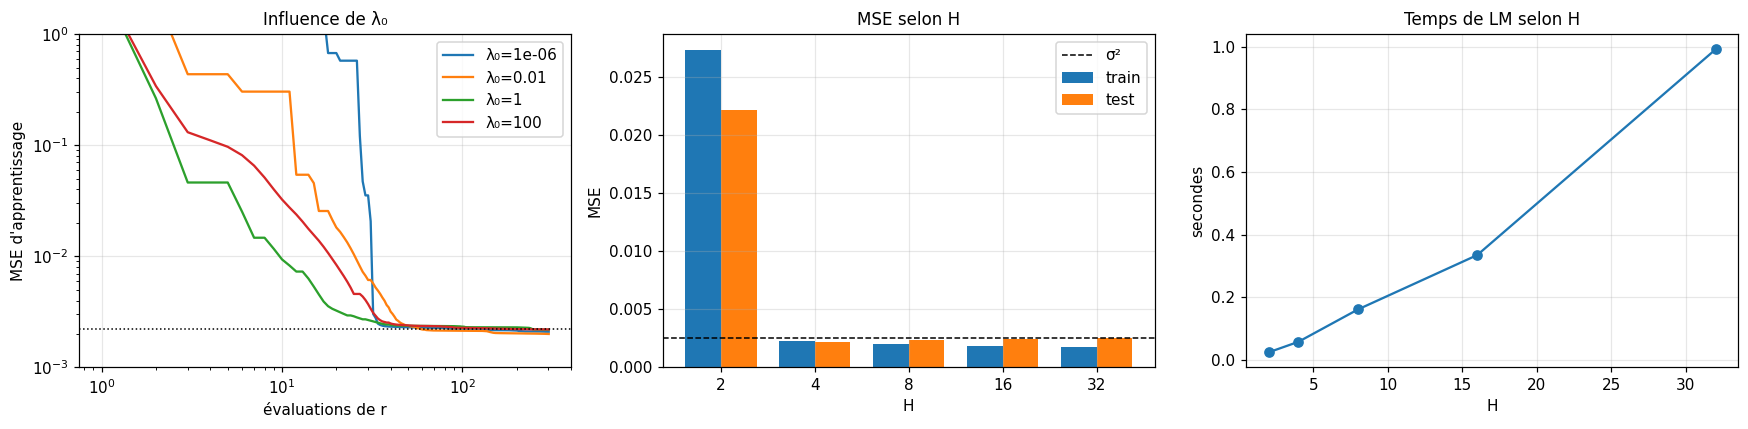

In [62]:
# Expérience 2 : influence de λ0
lam0s = [1e-6, 1e-2, 1, 100]
res_lam = {}
for l0 in lam0s:
    res_lam[l0] = levenberg_marquardt(residuals, jacobian, p_init, lam0=l0, rule="book", max_iter=300, tol_f=0)
print("Influence de λ₀ (règle book) :")
for l0, o in res_lam.items():
    print(f"  λ₀={l0:<8g} MSE={mse_tr(o.x):.5f}  évaluations totales={o.nfev:<4d} évaluations → cible={evals_to_target(lm_costs(o))}  pas rejetés={o.n_rejected}")

# Expérience 3 : influence de H (moyenne sur 5 initialisations)
Hs = [2, 4, 8, 16, 32]
res_H = {}
for h_ in Hs:
    f_, r_, j_, n_ = make_net(h_, x_tr, y_tr)
    trs, tes, tms = [], [], []
    for s in range(5):
        p0_ = 0.5 * np.random.default_rng(10 + s).standard_normal(n_)
        t = time.perf_counter(); o = levenberg_marquardt(r_, j_, p0_, lam0=1e-2, max_iter=300, tol_f=0); tms.append(time.perf_counter() - t)
        trs.append(np.mean(r_(o.x) ** 2)); tes.append(np.mean((f_(o.x, x_te)[0] - y_te) ** 2))
    res_H[h_] = (np.mean(trs), np.mean(tes), np.mean(tms), n_)
print("\nInfluence de H (moyenne de 5 initialisations) :")
for h_, (a, b, tt, n_) in res_H.items():
    print(f"  H={h_:<3d} n={n_:<4d} MSE train={a:.5f}  MSE test={b:.5f}  temps={tt:.4f}s")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for l0, o in res_lam.items():
    ax[0].loglog(np.arange(1, len(lm_costs(o)) + 1), mse_curve(lm_costs(o)), label=f"λ₀={l0:g}")
ax[0].axhline(MSE_CIBLE, color="k", ls=":", lw=1); ax[0].set_ylim(1e-3, 1.0)
ax[0].set(title="Influence de λ₀", xlabel="évaluations de r", ylabel="MSE d'apprentissage"); ax[0].legend()
w = 0.38; pos = np.arange(len(Hs))
ax[1].bar(pos - w / 2, [res_H[h][0] for h in Hs], w, label="train"); ax[1].bar(pos + w / 2, [res_H[h][1] for h in Hs], w, label="test")
ax[1].axhline(SIGMA ** 2, color="k", ls="--", lw=1, label="σ²")
ax[1].set_xticks(pos); ax[1].set_xticklabels(Hs); ax[1].set(title="MSE selon H", xlabel="H", ylabel="MSE"); ax[1].legend()
ax[2].plot(Hs, [res_H[h][2] for h in Hs], "o-"); ax[2].set(title="Temps de LM selon H", xlabel="H", ylabel="secondes")
plt.tight_layout(); plt.show()

### Expérience 4 — robustesse sur 30 initialisations
LM converge vers un minimum **local** : le résultat dépend de l'initialisation. On compare la dispersion de la MSE finale pour LM et pour la descente de gradient (mêmes 30 initialisations).

LM : médiane=0.00204  min=0.00185  max=0.00218  écart-type=0.00009
GD : médiane=0.00367  min=0.00280  max=0.02606  écart-type=0.00421
Cible atteinte (MSE ≤ 0.0022) : LM 30/30 (médiane 103 évaluations) ; GD 0/30 (jamais en 2000 itérations)
Runs dans 2× le plancher σ² : LM 30 / 30 ; GD 25 / 30


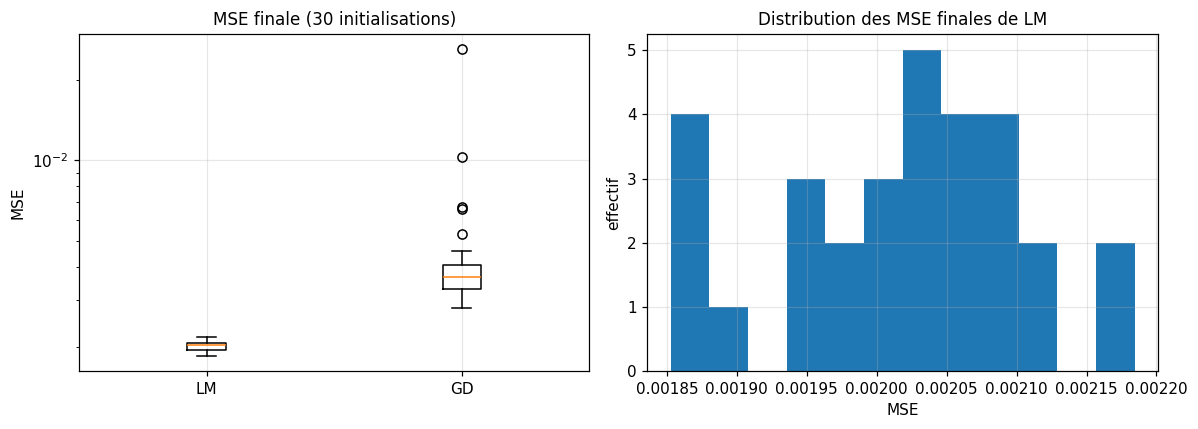

In [63]:
finals_lm, finals_gd, ev_lm, ev_gd = [], [], [], []
for s in range(30):
    p0_ = 0.5 * np.random.default_rng(100 + s).standard_normal(n_params)
    o = levenberg_marquardt(residuals, jacobian, p0_, lam0=1e-2, max_iter=300, tol_f=0)
    finals_lm.append(mse_tr(o.x)); ev_lm.append(evals_to_target(lm_costs(o)))
    xg_, hg_ = gradient_descent(residuals, jacobian, p0_)
    finals_gd.append(mse_tr(xg_)); ev_gd.append(evals_to_target(hg_))

for name, f in [("LM", finals_lm), ("GD", finals_gd)]:
    print(f"{name} : médiane={np.median(f):.5f}  min={np.min(f):.5f}  max={np.max(f):.5f}  écart-type={np.std(f):.5f}")
ok_lm = [e for e in ev_lm if e is not None]; ok_gd = [e for e in ev_gd if e is not None]
print(f"Cible atteinte (MSE ≤ {MSE_CIBLE}) : LM {len(ok_lm)}/30 (médiane {int(np.median(ok_lm))} évaluations) ; GD {len(ok_gd)}/30" + (f" (médiane {int(np.median(ok_gd))})" if ok_gd else " (jamais en 2000 itérations)"))
print("Runs dans 2× le plancher σ² : LM", int(np.sum(np.array(finals_lm) < 2 * SIGMA ** 2)), "/ 30 ; GD", int(np.sum(np.array(finals_gd) < 2 * SIGMA ** 2)), "/ 30")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].boxplot([finals_lm, finals_gd]); ax[0].set_xticklabels(["LM", "GD"]); ax[0].set_yscale("log"); ax[0].set(title="MSE finale (30 initialisations)", ylabel="MSE")
ax[1].hist(finals_lm, bins=12); ax[1].set(title="Distribution des MSE finales de LM", xlabel="MSE", ylabel="effectif")
plt.tight_layout(); plt.show()

### Expériences 5 et 6 — pourquoi λ ? et quelles variantes ?
**5. Gauss–Newton pur contre LM** : on exécute Gauss–Newton **sans amortissement ni test** (le pas est pris tel quel, même s'il augmente le coût) depuis 10 initialisations ; il suffit à montrer l'instabilité loin de l'optimum.

**6. Variantes de LM** : amortissement $D=I$ (Levenberg) contre $D=\mathrm{diag}(J^\top J)$ (Marquardt), croisé sur 20 initialisations.

Exp. 5 — runs convergés (MSE ≤ 2σ²) sur 10 : Gauss–Newton pur = 0, LM = 10
         Gauss–Newton pur : 10/10 runs où le coût AUGMENTE à au moins une itération

Exp. 6 — amortissement  règle λ   MSE médiane  éval. → cible (méd.)  cible atteinte   ≤ 2σ²
D = I                   book          0.00204                    98           20/20   20/20
D = I                   gain          0.00210                   134           19/20   20/20
D = diag(JᵀJ)           book          0.00212                   120           17/20   20/20
D = diag(JᵀJ)           gain          0.00212                    91           19/20   20/20


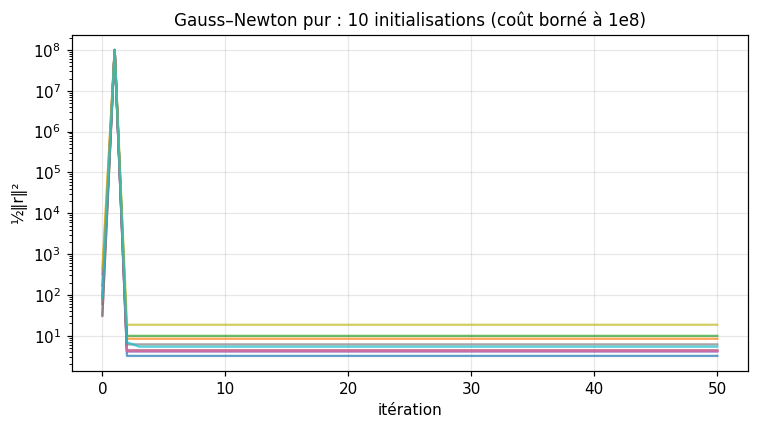

In [64]:
seuil = 2 * SIGMA ** 2        # « convergé » = MSE d'apprentissage ≤ 2× le plancher de bruit

# Expérience 5
gn_curves, ok_gn, ok_lm5 = [], 0, 0
for s in range(10):
    p0_ = 0.5 * np.random.default_rng(200 + s).standard_normal(n_params)
    _, _, hg = gauss_newton(residuals, jacobian, p0_, max_iter=50)
    o = levenberg_marquardt(residuals, jacobian, p0_, lam0=1e-2, max_iter=300, tol_f=0)
    gn_curves.append(hg)
    ok_gn += int(np.isfinite(hg[-1]) and 2 * hg[-1] / m_tr < seuil)
    ok_lm5 += int(mse_tr(o.x) < seuil)
nb_croissances = sum(int(np.any(np.diff(np.where(np.isfinite(c), c, 1e300)) > 0)) for c in gn_curves)
print(f"Exp. 5 — runs convergés (MSE ≤ 2σ²) sur 10 : Gauss–Newton pur = {ok_gn}, LM = {ok_lm5}")
print(f"         Gauss–Newton pur : {nb_croissances}/10 runs où le coût AUGMENTE à au moins une itération")

# Expérience 6
configs = [("identity", "book"), ("identity", "gain"), ("marquardt", "book"), ("marquardt", "gain")]
tab6 = {}
for dmp, rl in configs:
    fin, evs, ok_ = [], [], 0
    for s in range(20):
        p0_ = 0.5 * np.random.default_rng(300 + s).standard_normal(n_params)
        o = levenberg_marquardt(residuals, jacobian, p0_, lam0=1e-2, max_iter=300, tol_f=0, damping=dmp, rule=rl)
        fin.append(mse_tr(o.x)); e_ = evals_to_target(lm_costs(o)); evs.append(np.nan if e_ is None else e_)
        ok_ += int(mse_tr(o.x) < seuil)
    tab6[(dmp, rl)] = (np.median(fin), np.nanmedian(evs), int(np.sum(~np.isnan(evs))), ok_)
print(f"\n{'Exp. 6 — amortissement':<24}{'règle λ':<9}{'MSE médiane':>12}{'éval. → cible (méd.)':>22}{'cible atteinte':>16}{'≤ 2σ²':>8}")
for (dmp, rl), (a, b, c, d) in tab6.items():
    print(f"{('D = I' if dmp == 'identity' else 'D = diag(JᵀJ)'):<24}{rl:<9}{a:>12.5f}{b:>22.0f}{str(c) + '/20':>16}{str(d) + '/20':>8}")

plt.figure(figsize=(7, 4))
for c in gn_curves:
    plt.semilogy(np.clip(c, 1e-3, 1e8), alpha=.7)
plt.title("Gauss–Newton pur : 10 initialisations (coût borné à 1e8)"); plt.xlabel("itération"); plt.ylabel("½‖r‖²")
plt.tight_layout(); plt.show()

## 11. Variante classification : deux lunes (sortie sigmoïde, erreur quadratique)

LM exige des moindres carrés. Pour classer, on prend une sortie sigmoïde $s=\sigma(z)$ et le résidu $r_i=s_i-y_i$ avec $y_i\in\{0,1\}$. **L'entropie croisée ne rentre pas dans ce cadre** (ce n'est pas une somme de carrés) : c'est une limite de la méthode. Réseau $2\to H\to1$ ; la jacobienne contient le facteur $\sigma'(z)=\sigma(z)(1-\sigma(z))$.

Erreur jacobienne : 1.292329299129591e-10
LM    : précision train = 0.993, test = 0.933, essais = 183, temps = 0.155s
scipy : précision train = 0.993, test = 0.933, éval = 474
GD    : précision train = 0.975, test = 0.967, itérations = 2000


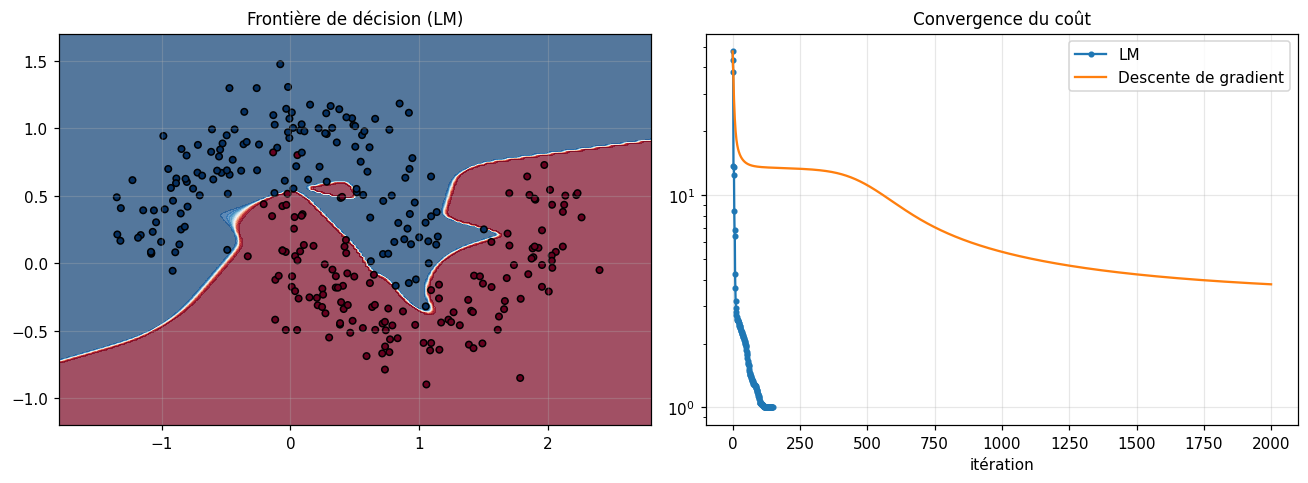

In [65]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

Xm, ym = make_moons(n_samples=400, noise=0.2, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.3, random_state=0, stratify=ym)

def make_clf(Hc, X, y):
    def unpack(p):
        return p[:2 * Hc].reshape(2, Hc), p[2 * Hc:3 * Hc], p[3 * Hc:4 * Hc], p[4 * Hc]
    def forward(p, XX):
        W1, b1, W2, b2 = unpack(p)
        h = np.tanh(XX @ W1 + b1)
        return 1 / (1 + np.exp(-(h @ W2 + b2))), h
    def residuals(p):
        return forward(p, X)[0] - y
    def jacobian(p):
        W1, b1, W2, b2 = unpack(p)
        s, h = forward(p, X)
        ds = (s * (1 - s))[:, None]                    # dσ/dz
        dh = W2 * (1 - h ** 2)
        return np.hstack([ds * dh * X[:, [0]], ds * dh * X[:, [1]], ds * dh, ds * h, ds])
    return forward, residuals, jacobian, 4 * Hc + 1

Hc = 8
fc, rc, jc, nc = make_clf(Hc, Xtr, ytr)
p0c = 0.5 * np.random.default_rng(0).standard_normal(nc)
print("Erreur jacobienne :", check_jacobian(rc, jc, p0c))

acc = lambda p, X, y: np.mean((fc(p, X)[0] > 0.5) == y)
t = time.perf_counter(); o_c = levenberg_marquardt(rc, jc, p0c, lam0=1e-2, max_iter=500, tol_f=1e-6); tc = time.perf_counter() - t
print(f"LM    : précision train = {acc(o_c.x, Xtr, ytr):.3f}, test = {acc(o_c.x, Xte, yte):.3f}, essais = {o_c.n_iter}, temps = {tc:.3f}s")
solc = least_squares(rc, p0c, jac=jc, method="lm")
print(f"scipy : précision train = {acc(solc.x, Xtr, ytr):.3f}, test = {acc(solc.x, Xte, yte):.3f}, éval = {solc.nfev}")
pg, hgc = gradient_descent(rc, jc, p0c, lr=5e-3, max_iter=2000)
print(f"GD    : précision train = {acc(pg, Xtr, ytr):.3f}, test = {acc(pg, Xte, yte):.3f}, itérations = {len(hgc)}")

gx_, gy_ = np.meshgrid(np.linspace(-1.8, 2.8, 200), np.linspace(-1.2, 1.7, 200))
zz = fc(o_c.x, np.c_[gx_.ravel(), gy_.ravel()])[0].reshape(gx_.shape)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].contourf(gx_, gy_, zz, levels=20, cmap="RdBu_r", alpha=.7)
ax[0].scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, cmap="RdBu_r", edgecolor="k", s=18); ax[0].set_title("Frontière de décision (LM)")
ax[1].semilogy(o_c.F_hist, "o-", ms=3, label="LM"); ax[1].semilogy(hgc, label="Descente de gradient")
ax[1].set(title="Convergence du coût", xlabel="itération"); ax[1].legend()
plt.tight_layout(); plt.show()